# Import libraries

In [1]:
from functions.functions_segmentation_benchmark import workflow_segmentation_error
import pandas as pd
import os
import matplotlib.pyplot as plt
import math
import numpy as np


# Parameters

In [2]:
# microwells to delete because no correspondance between video and nomenclature
# (the nomenclature name is wrong)
bad_mw = ["TR9-C01_tile008_a4",\
          "(HPC_3000)_tile009_d1"]
# path in which we save the figures for the paper   
path_save = r"Figures"
os.makedirs(path_save, exist_ok=True)
# filtering index
name_index = "Osc_index-9"
# for plotting
label_map = {
    'HSC_2000': 'HSC',
    'HPC_3000': 'CD34+', #'HPC'
    'MPP_epp':  'MPP',
    'LMPP_epp': 'LMPP',
    'TR1-A01':  'BMS-265246',
    'TR3-A03':  'Venetoclax',
    'TR5-B04':  'JQ-1',
    'TR7-B02':  'Palbociclib',
    'TR9-C01':  'Control',
}

datatype_groups = {
    'Cell Line': ['TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01'],
    'Cord Blood': ['HSC_2000', 'MPP_epp', 'LMPP_epp', 'HPC_3000']}

# Marker map for the 9 conditions
marker_map = {
    # Cell Lines (Group 1)
    'TR1-A01': 'D',  # Diamond
    'TR3-A03': 'P',  # Plus
    'TR5-B04': '*',  # Star
    'TR7-B02': 'X',  # X
    'TR9-C01': 'h',  # Hexagon
    
    # Cord Blood (Group 2)
    #'HSC_2000': 's', # Square
    'HPC_3000': 'o', # Circle
    #'MPP_epp':  'v', # Triangle down
    #'LMPP_epp': '^', # Triangle up

}


# Cellpose groundtruth

## Load groundtruth and results

In [3]:
# path for results and groundtruth
cellpose_results = r"..\groundtruth\Cellpose" 
gt_path = "../groundtruth"

# extract the groundtruths in a dataframe
name_gt = "MB_Groundtruths_corrected.xlsx"
sheet_names = ["MB_250807", "MB_251003"]
dfs = []
for sheet_name in sheet_names: # read each sheet
    df = pd.read_excel(os.path.join(gt_path, name_gt), sheet_name=sheet_name)
    dfs.append(df)
df_gt = pd.concat(dfs, axis=1) # concatenate by column
df_gt.columns = df_gt.iloc[0] # the first row becomes the header column name
df_gt = df_gt[1:].reset_index(drop=True) # take only the values
# drop the bad nomenclature wells
df_gt = df_gt.drop(bad_mw, axis=1)

In [4]:
# drop HSC, LMPP, MPP
print(len(df_gt.columns))
pattern_to_drop = r'^\((HSC_2000|LMPP_epp|MPP_epp)\)'
df_gt = df_gt.drop(columns=df_gt.filter(regex=pattern_to_drop).columns)
print(len(df_gt.columns))

93
63


## Analysis up to 9 cells

### Before correction

Without filtering

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile088_c3_HSC_

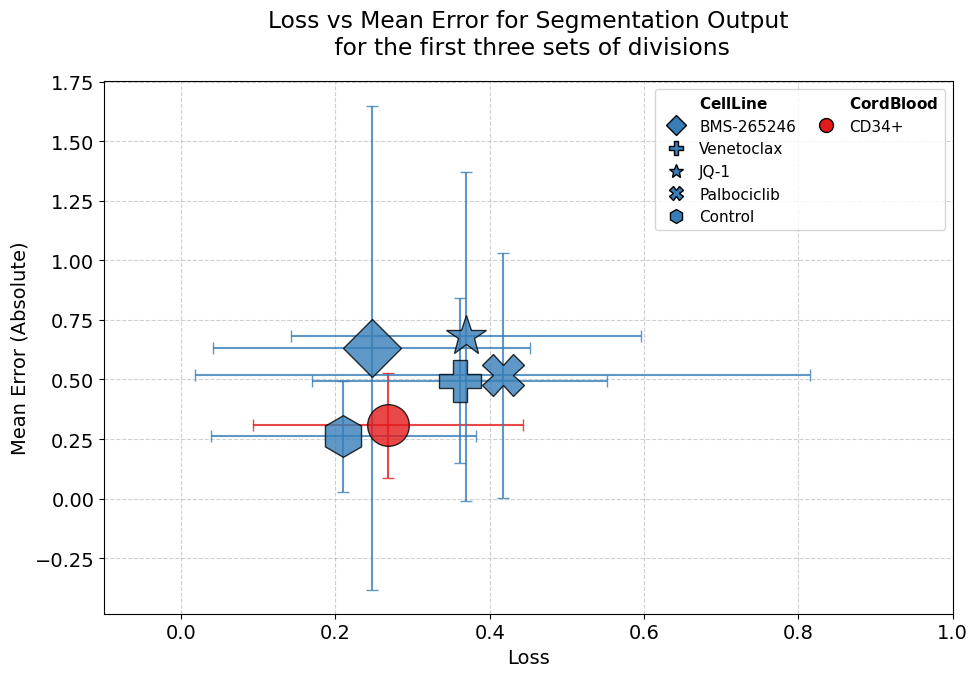

'\n_, _, _, _= workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",                            flag_filter=False, thresh_score=None, name_index = None, comp_type="nine",                            x_var_name="mean_error_norm", y_var_name="mean_error",                            title_plot="Mean Error Normalized vs Mean Error Absolute for Segmentation Output\n for the first three sets of divisions",                            x_label="Mean Error (Normalized)", y_label="Mean Error (Absolute)",                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\n                            mode_aggregation="aggr_mean",                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_bc_threshNone_nine_mean_mea_aggrmean")\n'

In [5]:
_, df_cellpose_wof_bc, _, grouped_results_wof_bc = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="nine",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_bc_threshNone_nine_loss_mea_aggrmean")
"""
_, _, _, _= workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="nine",\
                            x_var_name="mean_error_norm", y_var_name="mean_error",\
                            title_plot="Mean Error Normalized vs Mean Error Absolute for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Mean Error (Normalized)", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_bc_threshNone_nine_mean_mea_aggrmean")
"""

With filtering

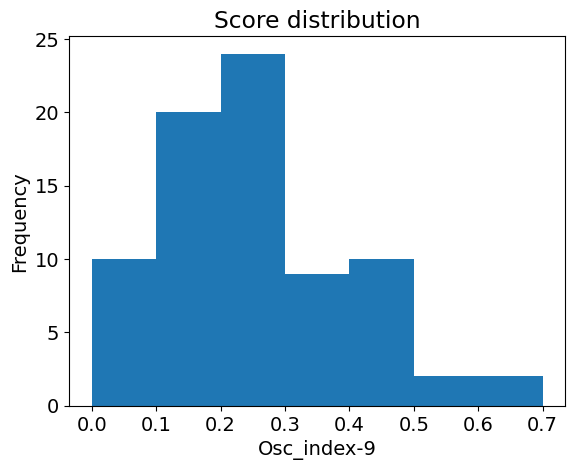

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile104_a3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(LMPP_epp)_tile057_a4_LMPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile035_b2_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile054_b3_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile083_c4_MPP_epp_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


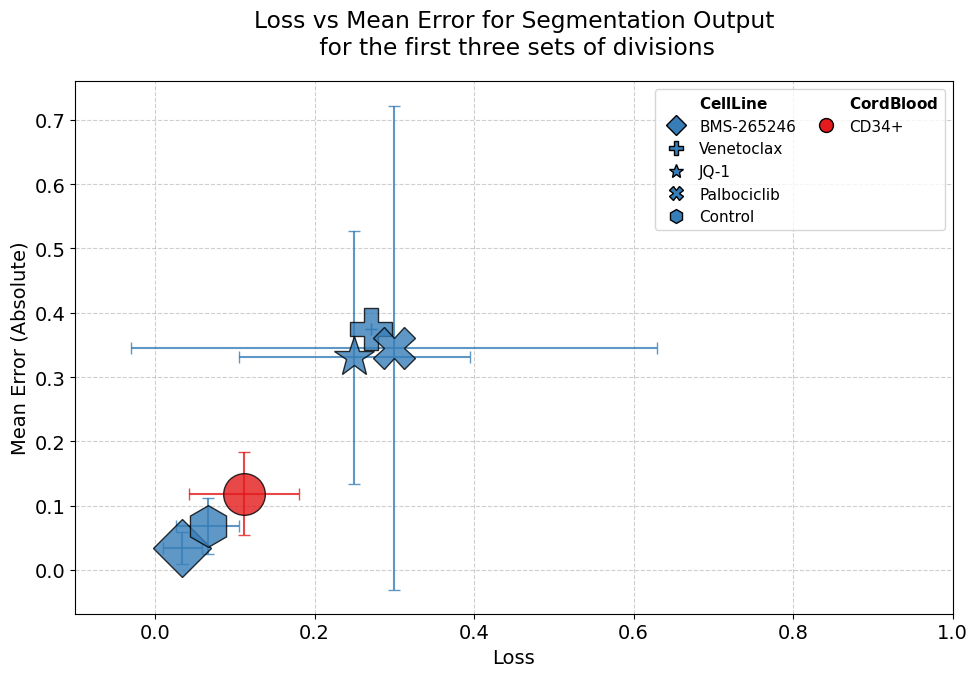

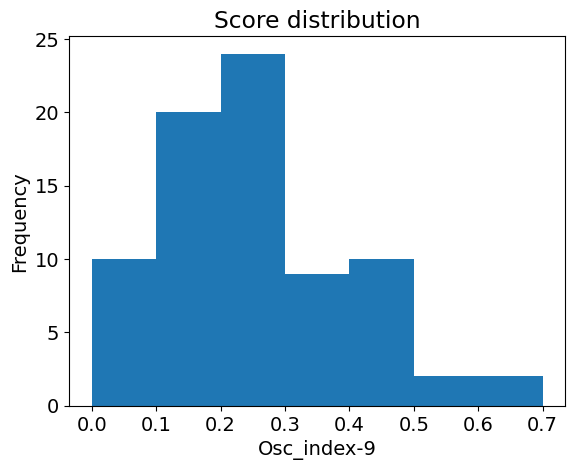

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile104_a3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(LMPP_epp)_tile057_a4_LMPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile035_b2_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile054_b3_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile083_c4_MPP_epp_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


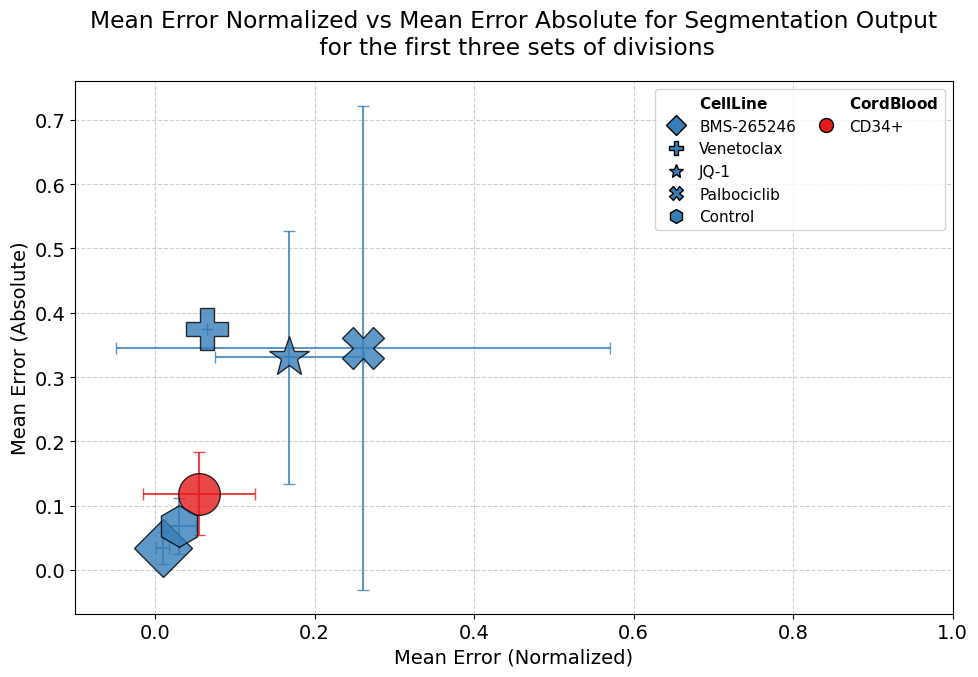

In [6]:
_, df_cellpose_wtf_bc, _, grouped_results_wtf_bc = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=True, thresh_score=0.2, name_index = name_index, comp_type="nine",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_bc_thresh02_nine_loss_mea_aggrmean")

_, _, _, grouped_results_wtf_bc_normalized= workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=True, thresh_score=0.2, name_index = name_index, comp_type="nine",\
                            x_var_name="mean_error_norm", y_var_name="mean_error",\
                            title_plot="Mean Error Normalized vs Mean Error Absolute for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Mean Error (Normalized)", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_bc_thresh02_nine_mean_mea_aggrmean")

### After correction

Without filtering

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile088_c3_HSC_

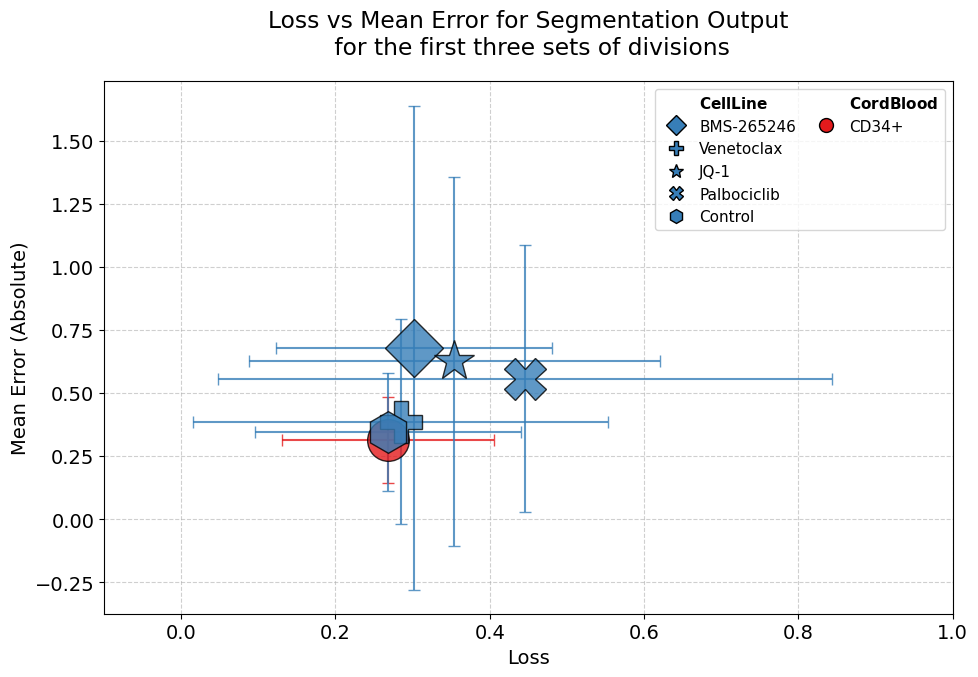

'\n_, _, _, _ = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Correction",                            flag_filter=None, thresh_score=None, name_index = None, comp_type="nine",                            x_var_name="mean_error_norm", y_var_name="mean_error",                            title_plot="Mean Error Normalized vs Mean Error Absolute for Segmentation Output\n for the first three sets of divisions",                            x_label="Mean Error (Normalized)", y_label="Mean Error (Absolute)",                            datatype_groups=datatype_groups, label_map=label_map, mode_aggregation="aggr_mean",                            flag_save=True, path_save = path_save, name_fig = "fig_ac_threshNone_nine_mean_mea_aggrmean")\n'

In [7]:
_, df_cellpose_wof_ac, _, grouped_results_wof_ac = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Correction",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="nine",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_ac_threshNone_nine_loss_mea_aggrmean")

"""
_, _, _, _ = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Correction",\
                            flag_filter=None, thresh_score=None, name_index = None, comp_type="nine",\
                            x_var_name="mean_error_norm", y_var_name="mean_error",\
                            title_plot="Mean Error Normalized vs Mean Error Absolute for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Mean Error (Normalized)", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_ac_threshNone_nine_mean_mea_aggrmean")
"""

With filtering: panel 4c

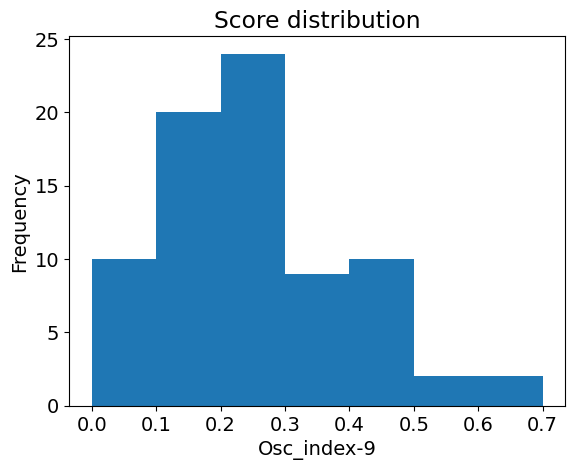

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile104_a3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(LMPP_epp)_tile057_a4_LMPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile035_b2_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile054_b3_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile083_c4_MPP_epp_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


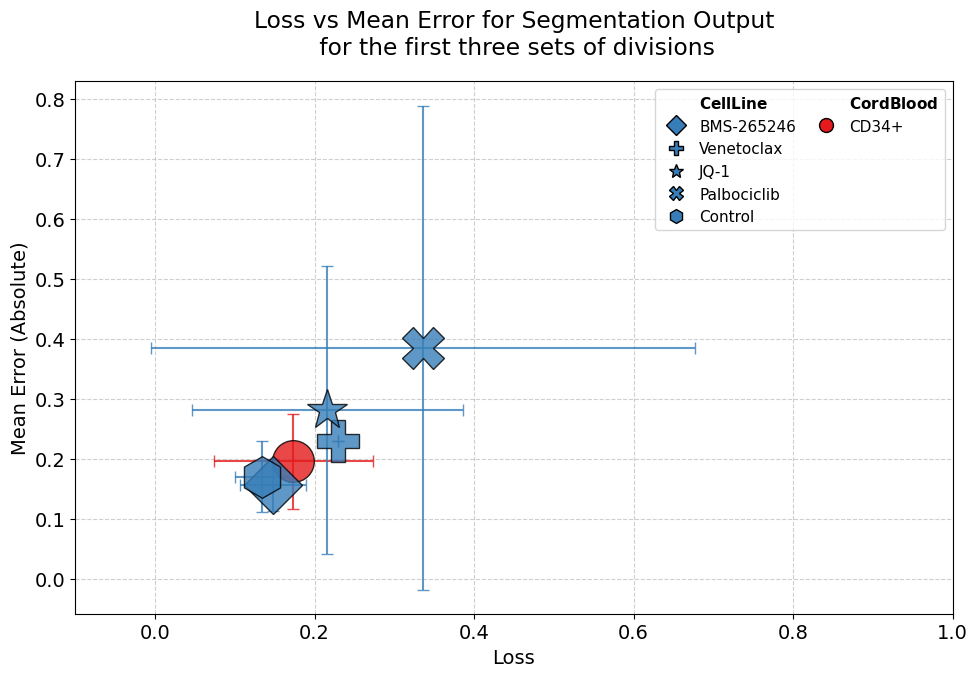

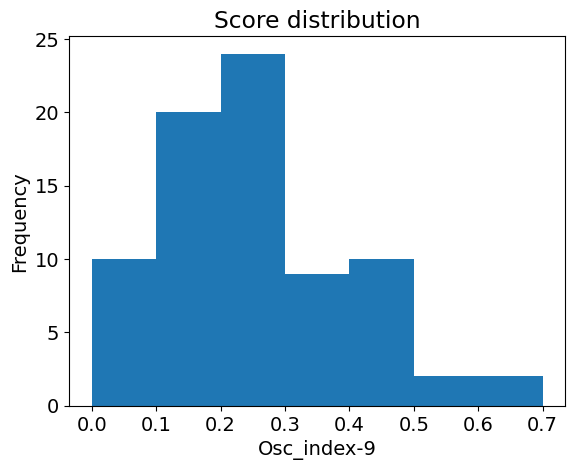

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile104_a3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(LMPP_epp)_tile057_a4_LMPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile035_b2_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile054_b3_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile083_c4_MPP_epp_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


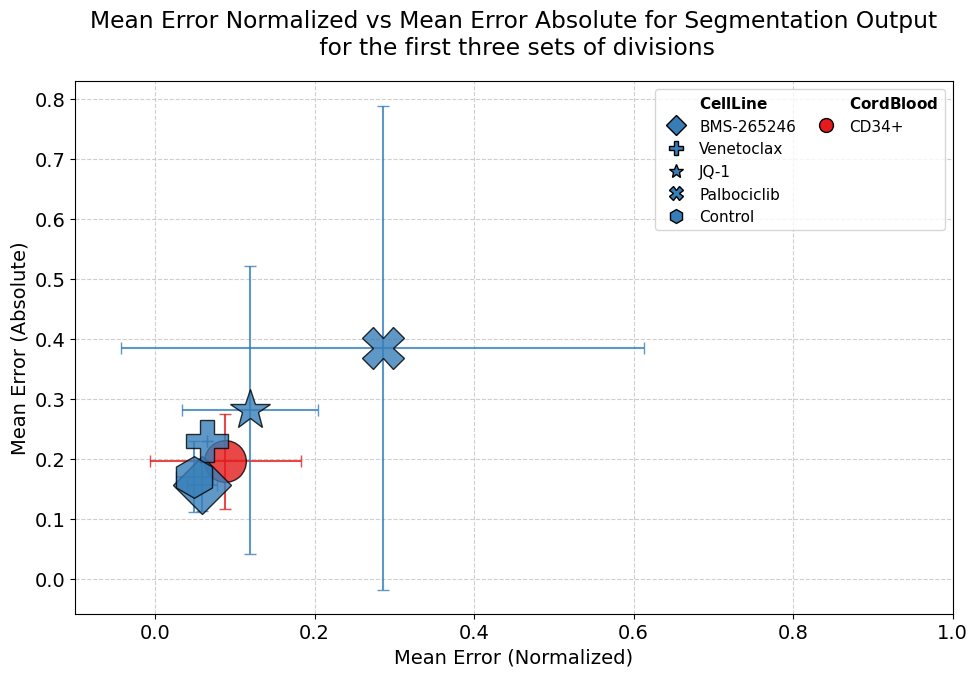

In [8]:
_, df_cellpose_wtf_ac, _, grouped_results_wtf_ac = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Correction",\
                            flag_filter=True, thresh_score=0.2, name_index = name_index, comp_type="nine",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_ac_thresh02_nine_loss_mea_aggrmean")


_, _, _,grouped_results_wtf_ac_normalized= workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Correction",\
                            flag_filter=True, thresh_score=0.2, name_index = name_index, comp_type="nine",\
                            x_var_name="mean_error_norm", y_var_name="mean_error",\
                            title_plot="Mean Error Normalized vs Mean Error Absolute for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Mean Error (Normalized)", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_ac_thresh02_nine_mean_mea_aggrmean")



### Comparison before vs after filtering

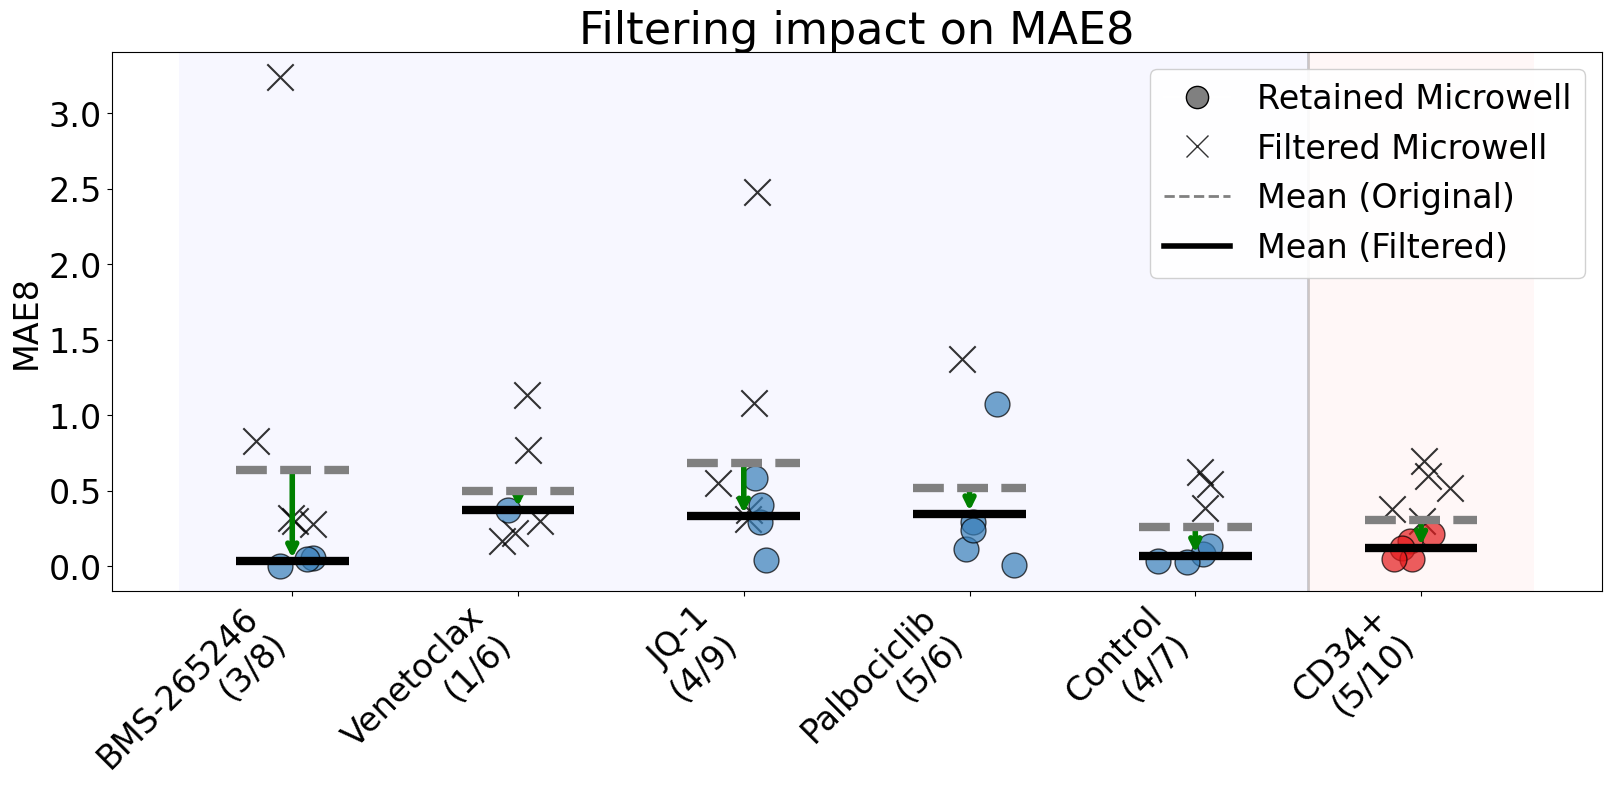

In [9]:
def plot_filtering_impact(grouped_bc, grouped_ac, datatype_groups, label_map=None, 
                          y_var="mean_error", y_label="Mean Error", title=None,\
                          name_fig=None):
    """
    Shows how filtering improves the subtype mean by removing high-error tiles.
    Groups Cell Lines on the left and Cord Blood on the right.
    """
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.lines import Line2D
    import matplotlib

    # Setup Font 
    scale = 4
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.size': 5 * scale,
        'axes.labelsize': 6 * scale,
        'axes.titlesize': 8 * scale, # for axes
        'figure.titlesize': 7 * scale, # whole figure
        'xtick.labelsize': 6 * scale,
        'ytick.labelsize': 6 * scale,
        'legend.fontsize': 6 * scale,
    })

    
    # 1. Solidify condition order and group mapping
    all_conditions = []
    group_assignments = {} 
    for group_name, subtypes in datatype_groups.items():
        for st in subtypes:
            if st in grouped_bc: 
                all_conditions.append(st)
                group_assignments[st] = group_name

    fig, ax = plt.subplots(figsize=(4*scale, 2*scale), layout='constrained')
    x_positions = np.arange(len(all_conditions))
    base_colors = {'Cell Line': '#377eb8', 'Cord Blood': '#e41a1c'}
    
    display_labels = []

    # 2. Plotting loop per condition
    for i, condition in enumerate(all_conditions):
        color = base_colors[group_assignments[condition]]
        
        # Get data for THIS specific condition
        bc_samples = grouped_bc[condition]
        ac_samples = grouped_ac.get(condition, [])
        
        bc_values = [s[y_var] for s in bc_samples]
        bc_gts = [s['gt'] for s in bc_samples]
        ac_gts = [s['gt'] for s in ac_samples]
        
        # MEAN calculation
        mean_before = np.mean(bc_values)
        # Mean after is calculated only on survivors
        survivor_values = [s[y_var] for s in bc_samples if s['gt'] in ac_gts]
        mean_after = np.mean(survivor_values) if survivor_values else 0

        # Update labels for THIS condition
        clean_name = label_map.get(condition, condition) if label_map else condition
        display_labels.append(f"{clean_name}\n({len(ac_gts)}/{len(bc_gts)})")

        # Jitter for point distribution
        jitter = np.random.normal(0, 0.08, size=len(bc_values))
        
        for j, gt in enumerate(bc_gts):
            if gt in ac_gts:
                # SURVIVED: Bold color
                ax.scatter(i + jitter[j], bc_values[j], color=color, s=80*scale, 
                           edgecolors='black', alpha=0.7, zorder=3)
            else:
                # FILTERED: black 'x'
                ax.scatter(i + jitter[j], bc_values[j], color='black', s=90*scale, 
                           marker='x', alpha=0.8, zorder=2)

        # Plot Mean Markers
        ax.hlines(mean_before, i-0.25, i+0.25, colors='gray', linestyles='--', lw=1.5*scale, zorder=4)
        ax.hlines(mean_after, i-0.25, i+0.25, colors='black', lw=1.5*scale, zorder=4)
        
        # Optional: Arrow to highlight the drop
        if mean_after < mean_before and len(survivor_values) > 0:
            ax.annotate('', xy=(i, mean_after), xytext=(i, mean_before),
                        arrowprops=dict(arrowstyle='->', color='green', lw=1*scale, mutation_scale=4*scale))

    # 3. Aesthetics & Group Separation
    ax.set_xticks(x_positions)
    ax.set_xticklabels(display_labels, rotation=45, ha='right')
    ax.set_ylabel(y_label)
    ax.set_title(title or "Impact of Filtering on Population Mean")
    
    # Vertical divider between Cell Line and Cord Blood
    n_cell_line = len(datatype_groups[list(datatype_groups.keys())[0]])
    ax.axvline(x=n_cell_line - 0.5, color='black', linestyle='-', alpha=0.2, lw=2)
    
    # Adding background shading for groups to make it even clearer
    ax.axvspan(-0.5, n_cell_line - 0.5, facecolor='blue', alpha=0.03)
    ax.axvspan(n_cell_line - 0.5, len(all_conditions)-0.5, facecolor='red', alpha=0.03)

    # Custom Legend
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Retained Microwell', 
               markerfacecolor='gray', markersize=4*scale, markeredgecolor='black'),
        Line2D([0], [0], marker='x', color='black', linestyle='None', label='Filtered Microwell', markersize=4*scale, alpha=0.8),
        Line2D([0], [0], color='gray', linestyle='--', lw=0.5*scale, label='Mean (Original)'),
        Line2D([0], [0], color='black', lw=1*scale, label='Mean (Filtered)')
    ]
    ax.legend(handles=legend_elements, loc='upper right', frameon=True, framealpha=0.9)

    #plt.tight_layout()
    plt.show()

    fig.savefig(os.path.join(path_save, f"{name_fig}.png"), bbox_inches='tight', dpi=300)
    fig.savefig(os.path.join(path_save, f"{name_fig}.svg"), bbox_inches='tight')
    

    return fig

_ = plot_filtering_impact(grouped_results_wof_bc, grouped_results_wtf_bc,\
                             y_var = "mean_error", y_label = "MAE8",\
                            datatype_groups=datatype_groups, label_map=label_map,\
                            title="Filtering impact on MAE8",\
                            name_fig = "fig_cellpose_wof_vs_wfc_thresh02_nine_mea")

### Comparison before vs after correction

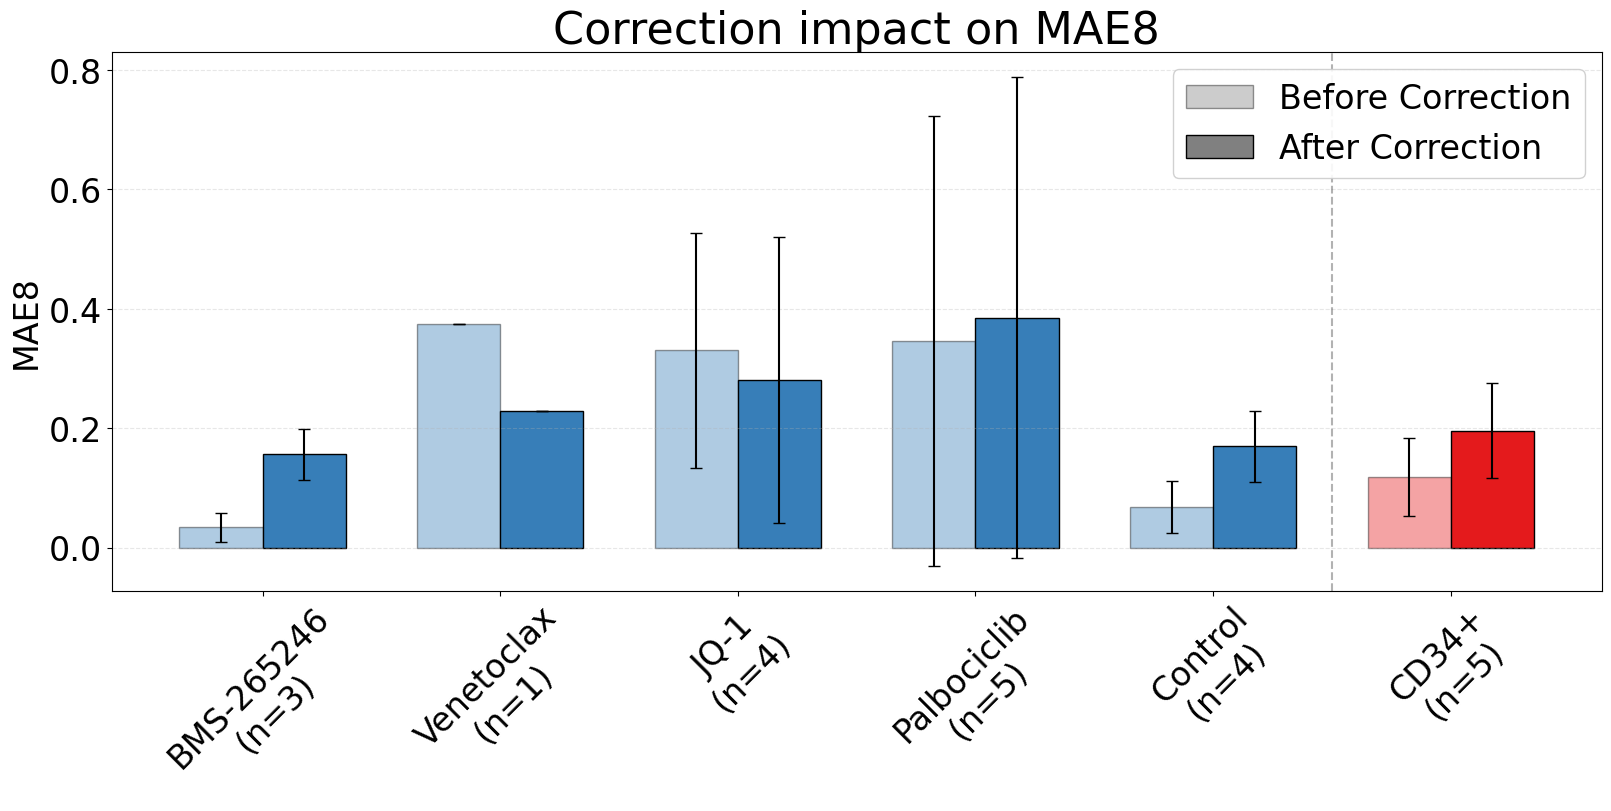

In [10]:
def plot_grouped_performance(grouped_bc, grouped_ac, datatype_groups, label_map=None, 
                             y_var="mean_error", y_label="Mean Error", title=None,\
                            name_fig=None, custom_label1=None, custom_label2=None):
    """
    Panel B: Bar chart grouped (BC vs AC) for each condition
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import matplotlib

    # Setup Font 
    scale = 4
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.size': 5 * scale,
        'axes.labelsize': 6 * scale,
        'axes.titlesize': 8 * scale, # for axes
        'figure.titlesize': 7 * scale, # whole figure
        'xtick.labelsize': 6 * scale,
        'ytick.labelsize': 6 * scale,
        'legend.fontsize': 6 * scale,
    })

    # Prepare order of conditions
    all_conditions = []
    group_assignments = {}
    for group_name, subtypes in datatype_groups.items():
        for st in subtypes:
            if st in grouped_bc: 
                all_conditions.append(st)
                group_assignments[st] = group_name

    # 2. Extract mean and std
    means_bc = [np.mean([s[y_var] for s in grouped_bc[c]]) for c in all_conditions]
    stds_bc = [np.std([s[y_var] for s in grouped_bc[c]]) for c in all_conditions]
    
    means_ac = [np.mean([s[y_var] for s in grouped_ac[c]]) for c in all_conditions]
    stds_ac = [np.std([s[y_var] for s in grouped_ac[c]]) for c in all_conditions]

    # nice labels
    #display_labels = [label_map.get(c, c) if label_map else c for c in all_conditions]
    display_labels = []
    for c in all_conditions:
        n_samples = len(grouped_bc[c])  # O len(grouped_ac[c])
        base_label = label_map.get(c, c) if label_map else c
        display_labels.append(f"{base_label}\n(n={n_samples})")

    # 3. Setup  bar position
    x = np.arange(len(all_conditions))
    width = 0.35  # bar width

    fig, ax = plt.subplots(figsize=(4*scale, 2*scale), layout='constrained')

    # 4. Colori
    # blue: cell line and red: cord blood as in panel A
    # BC = empty version (alpha), AC = full version
    base_colors = {'Cell Line': '#377eb8', 'Cord Blood': '#e41a1c'}
    colors_bc = [base_colors[group_assignments[c]] for c in all_conditions]
    
    # Plot bars Before Correction (BC)
    lbl1 = custom_label1 or 'Before Correction'
    lbl2 = custom_label2 or 'After Correction'
    rects1 = ax.bar(x - width/2, means_bc, width, yerr=stds_bc, label=lbl1,
                    color=colors_bc, alpha=0.4, edgecolor='black', capsize=1*scale)
    
    # Plot bars After Correction (AC)
    rects2 = ax.bar(x + width/2, means_ac, width, yerr=stds_ac, label=lbl2,
                    color=colors_bc, alpha=1.0, edgecolor='black', capsize=1*scale)

    # 5. Esthetic
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(display_labels, rotation=45)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Legend (BC vs AC)
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='gray', alpha=0.4, edgecolor='black', label=lbl1),
        Patch(facecolor='gray', alpha=1.0, edgecolor='black', label=lbl2)
    ]
    ax.legend(handles=legend_elements, loc='upper right', frameon=True, framealpha=0.9)

    # Line to divide the two macrogroups
    n_cell_line = len(datatype_groups[list(datatype_groups.keys())[0]])
    ax.axvline(x=n_cell_line - 0.5, color='black', linestyle='--', alpha=0.3)

    #plt.tight_layout()
    plt.show()


    fig.savefig(os.path.join(path_save, f"{name_fig}.png"), bbox_inches='tight', dpi=300)
    fig.savefig(os.path.join(path_save, f"{name_fig}.svg"), bbox_inches='tight')

    return fig

#_ = plot_grouped_performance(grouped_results_wof_bc, grouped_results_wtf_bc,\
#                             y_var = "mean_error", y_label = "Mean Error (Absolute)",\
#                            datatype_groups=datatype_groups, label_map=label_map,\
#                            title="Mean Error (Absolute) change without and with filtering",
#                            name_fig="fig_wof_vs_wfc_hist_thresh02_nine_mea")
_ = plot_grouped_performance(grouped_results_wtf_bc, grouped_results_wtf_ac,\
                             y_var = "mean_error", y_label = "MAE8",\
                            datatype_groups=datatype_groups, label_map=label_map,\
                            title="Correction impact on MAE8",
                            name_fig="fig_cellpose_bc_vs_ac_thresh02_nine_mea")

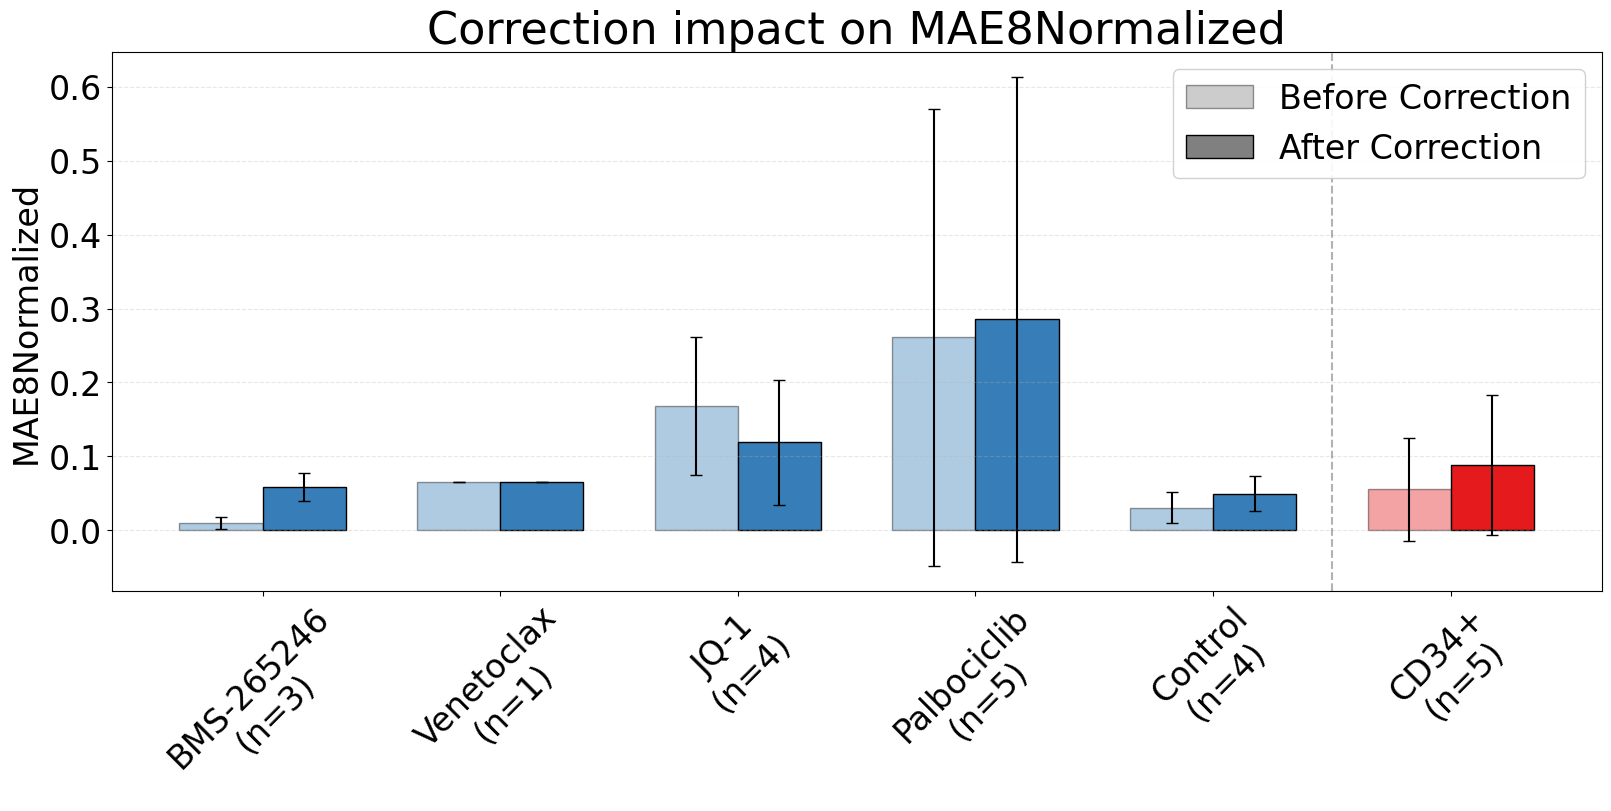

In [11]:
_ = plot_grouped_performance(grouped_results_wtf_bc_normalized, grouped_results_wtf_ac_normalized,\
                             y_var = "mean_error_norm", y_label = "MAE8Normalized",\
                            datatype_groups=datatype_groups, label_map=label_map,\
                            title="Correction impact on MAE8Normalized",
                            name_fig="fig_cellpose_bc_vs_ac_thresh02_nine_mea_normalized")

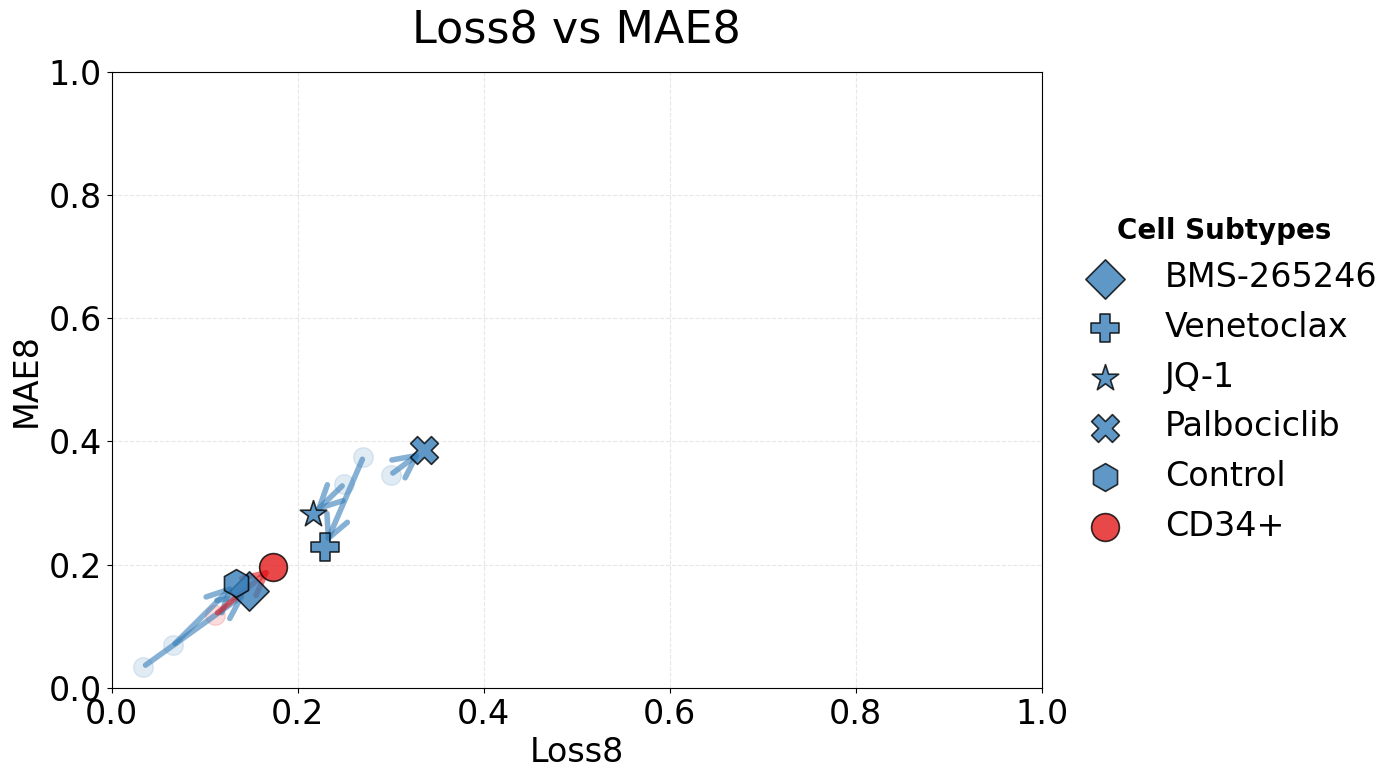

In [12]:
def plot_vector_shift_performance(grouped_filter, grouped_corr, datatype_groups, 
                                 marker_map, label_map=None, x_title="Loss", y_title="MAE",\
                                title=None, name_fig=None):
    """
    Panel C: Vector Shift Plot. 
    X-axis: Counting Loss (1 - index_exact)
    Y-axis: Segmentation Mean Error
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import matplotlib

    # Setup Font 
    scale = 4
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.size': 5 * scale,
        'axes.labelsize': 6 * scale,
        'axes.titlesize': 8 * scale, # for axes
        'figure.titlesize': 7 * scale, # whole figure
        'xtick.labelsize': 6 * scale,
        'ytick.labelsize': 6 * scale,
        'legend.fontsize': 6 * scale,
    })

    fig, ax = plt.subplots(figsize=(3*scale, 2*scale))
    
    base_colors = {'Cell Line': '#377eb8', 'Cord Blood': '#e41a1c'}
    
    for group_name, subtypes in datatype_groups.items():
        color = base_colors[group_name]
        
        for st in subtypes:
            if st in grouped_filter and st in grouped_corr:
                # Get lists
                list_filter = grouped_filter[st]
                list_corr = grouped_corr[st]
                
                if not list_filter or not list_corr:
                    continue

                # --- START POINT (After Filtering, Before Correction) ---
                x_start = np.mean([1 - s['index_exact'] for s in list_filter])
                y_start = np.mean([s['mean_error'] for s in list_filter])
                
                # --- END POINT (After Correction) ---
                x_end = np.mean([1 - s['index_exact'] for s in list_corr])
                y_end = np.mean([s['mean_error'] for s in list_corr])
                
                # Draw the vector
                ax.annotate('', 
                            xy=(x_end, y_end), 
                            xytext=(x_start, y_start),
                            arrowprops=dict(arrowstyle='->', 
                                            color=color, 
                                            lw=1*scale, 
                                            alpha=0.6,
                                            mutation_scale=10*scale))
                
                # Markers
                marker = marker_map.get(st, 'o')
                display_name = label_map.get(st, st) if label_map else st
                
                # Plot ghost start and solid end
                ax.scatter(x_start, y_start, color=color, alpha=0.15, s=50*scale, zorder=2)
                ax.scatter(x_end, y_end, color=color, marker=marker, s=100*scale, 
                           edgecolors='black', linewidths=0.3*scale, zorder=5, label=display_name, alpha=0.8)
                
    # Aesthetics
    ax.set_xlabel(x_title)# , fontweight='bold', #fontsize=11)
    ax.set_ylabel(y_title) #, fontweight='bold', #fontsize=11
    
    if title:
        ax.set_title(title, pad=20), #fontsize=14, fontweight='bold')
    
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)
    ax.grid(True, linestyle='--', alpha=0.3)

    # Professional Legend Fix
    handles, labels = ax.get_legend_handles_labels()
    # Create legend and store the object
    leg = ax.legend(handles, labels, loc='center left', bbox_to_anchor=(1, 0.5), 
                    frameon=False, title="Cell Subtypes")
    
    # Set the title fontweight manually
    plt.setp(leg.get_title(), fontweight='bold')

    # Visual Guide for "Target Area" (bottom-left corner)
    #ax.axvspan(0, 0.1, 0, 0.1, color='green', alpha=0.05)
    #ax.text(0.05, 0.05, "Target", color='green', alpha=0.3, fontweight='bold', transform=ax.get_xaxis_transform())

    #plt.tight_layout()
    plt.show()

    fig.savefig(os.path.join(path_save, f"{name_fig}.png"), bbox_inches='tight', dpi=300)
    fig.savefig(os.path.join(path_save, f"{name_fig}.svg"), bbox_inches='tight')


    return fig


# Assicurati di passare le medie DOPO il filtraggio e quelle DOPO la correzione
fig_panel_c = plot_vector_shift_performance(
    grouped_filter = grouped_results_wtf_bc, # After Filtering, Before Correction
    grouped_corr   = grouped_results_wtf_ac, # After Filtering, After Correction
    datatype_groups = datatype_groups,
    marker_map = marker_map,
    label_map = label_map,
    x_title="Loss8",
    y_title="MAE8",
    title = "Loss8 vs MAE8",
    name_fig = "fig_cellpose_bc_vs_ac_thresh02_nine_mea_sp"
)


In [13]:
print(grouped_results_wtf_bc["TR1-A01"])
#print(grouped_results_wtf_ac["TR1-A01"])

[{'gt': 'TR1-A01_tile069_b2', 'index_exact': 0.9444, 'std': np.float64(0.2354), 'mean_error': np.float64(0.05555555555555555), 'mean_error_norm': np.float64(0.01984126984126984)}, {'gt': 'TR1-A01_tile112_a4', 'index_exact': 0.9535, 'std': np.float64(0.2106), 'mean_error': np.float64(0.046511627906976744), 'mean_error_norm': np.float64(0.00988372093023256)}, {'gt': 'TR1-A01_tile163_a2', 'index_exact': 1.0, 'std': np.float64(0.0), 'mean_error': np.float64(0.0), 'mean_error_norm': np.float64(0.0)}]


## All frames data

### Before correction

Without filtering

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile088_c3_HSC_

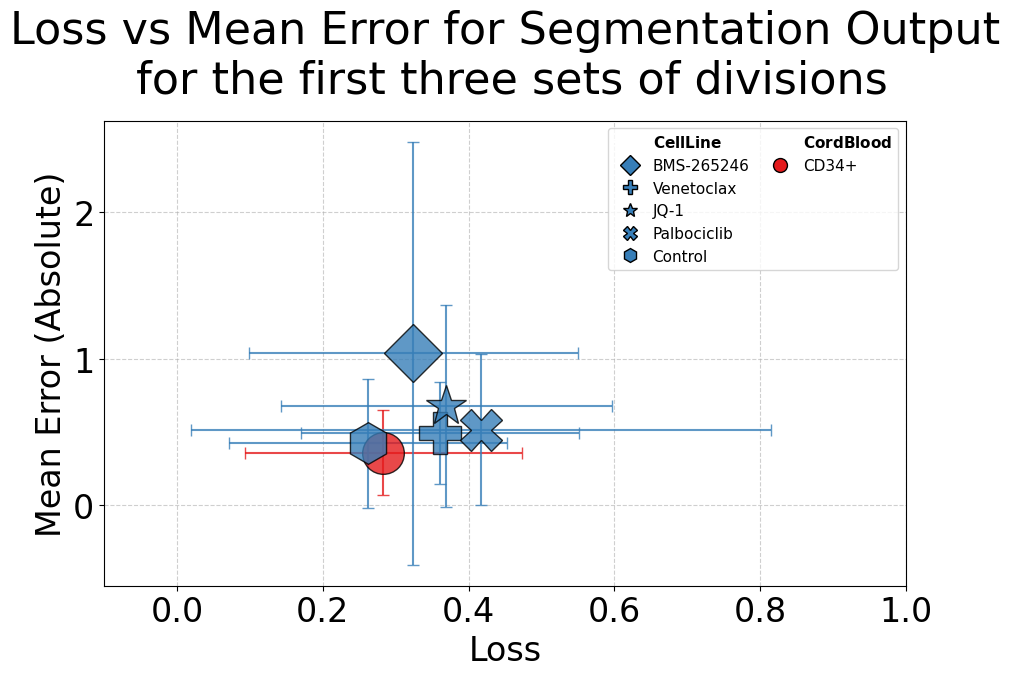

In [14]:
_, _, _, grouped_all_results_wof_bc = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="all",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_bc_threshNone_all_loss_mea_aggrmean")

With filtering

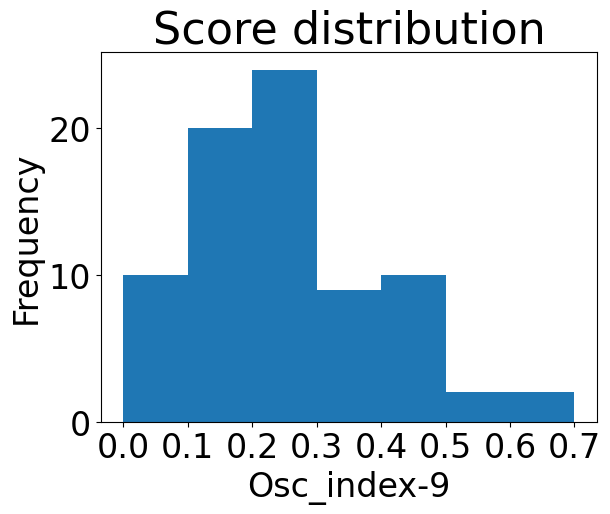

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile104_a3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(LMPP_epp)_tile057_a4_LMPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile035_b2_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile054_b3_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile083_c4_MPP_epp_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


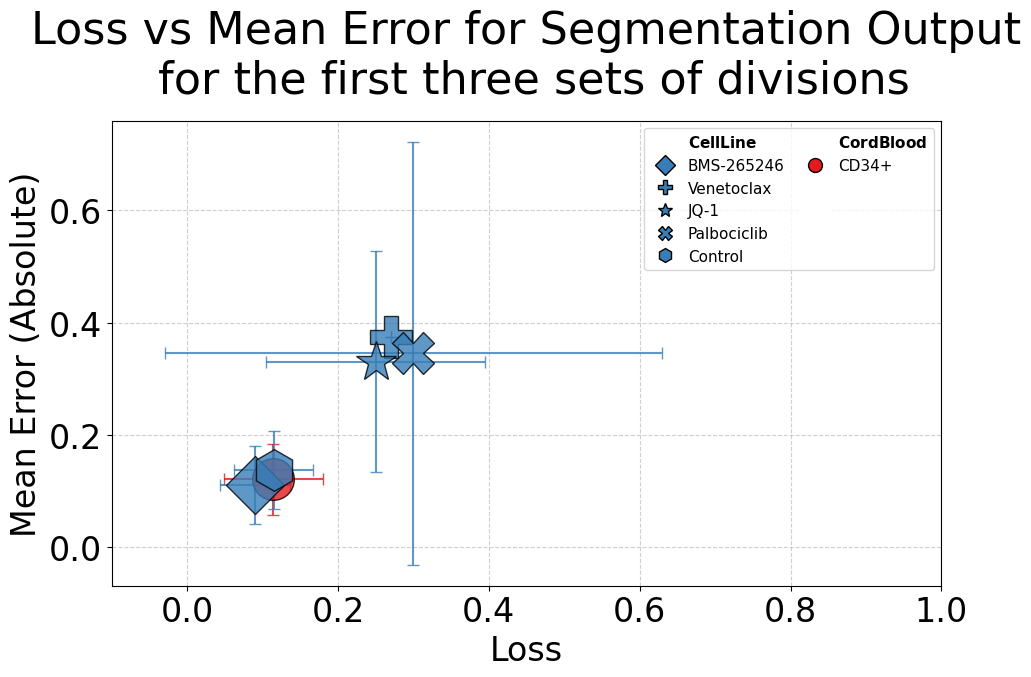

In [15]:
_, _, _, grouped_all_results_wtf_bc = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=True, thresh_score=0.2, name_index = name_index, comp_type="all",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_bc_thresh02_all_loss_mea_aggrmean")

### After correction

Before filtering

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile088_c3_HSC_

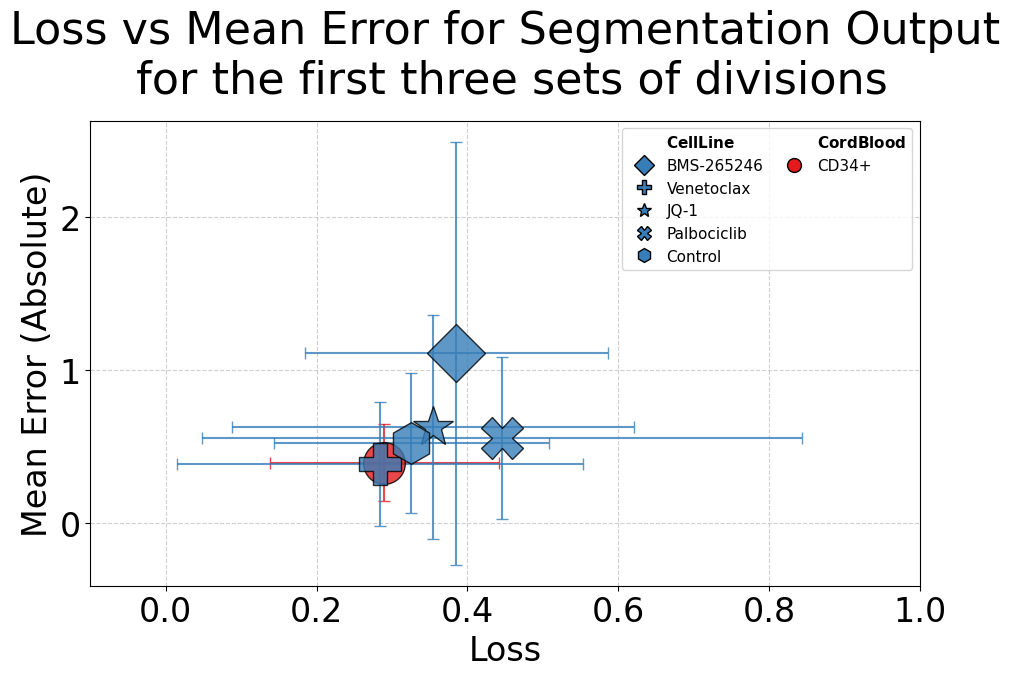

In [16]:
_, _, _, grouped_all_results_wof_ac = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Correction",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="all",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_ac_threshNone_all_loss_mea_aggrmean")


After filtering

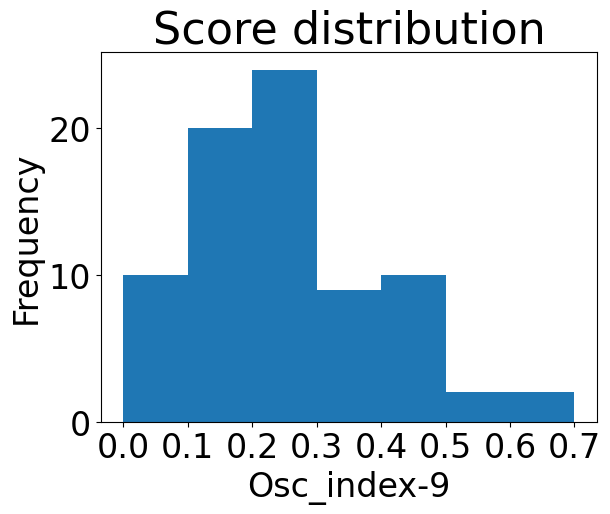

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile104_a3_HSC_2000_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(LMPP_epp)_tile057_a4_LMPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile035_b2_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile054_b3_MPP_epp_GT
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(MPP_epp)_tile083_c4_MPP_epp_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


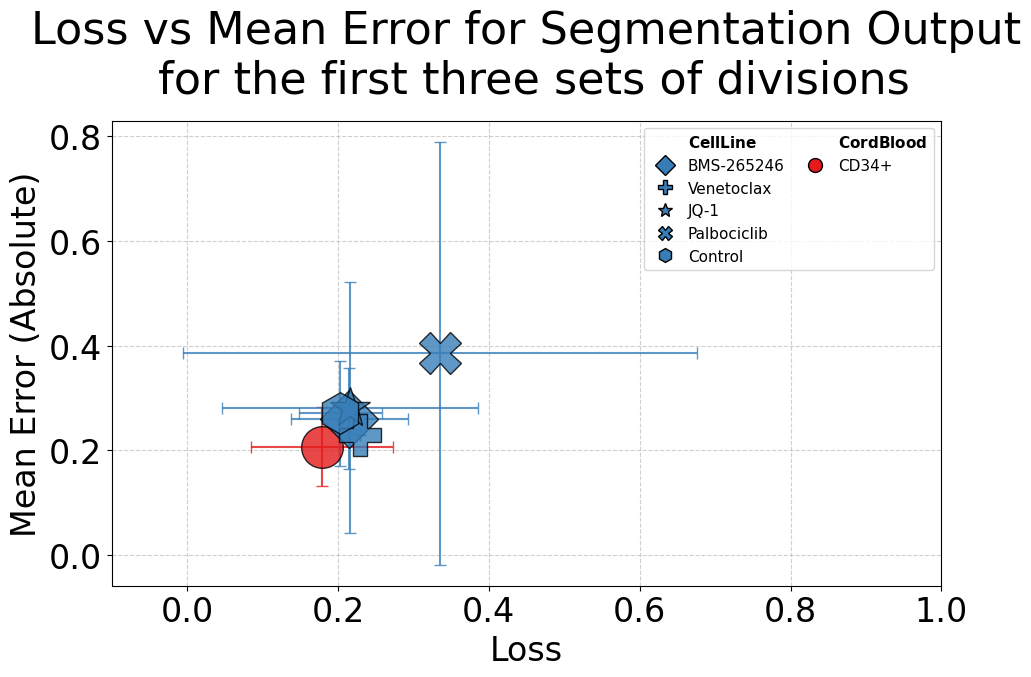

In [17]:
_, _, _, grouped_all_results_wtf_ac = workflow_segmentation_error(cellpose_results, df_results=None, df_gt=df_gt, col_name="Correction",\
                            flag_filter=True, thresh_score=0.2, name_index = name_index, comp_type="all",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_cellpose_ac_thresh02_all_loss_mea_aggrmean")


### Comparison

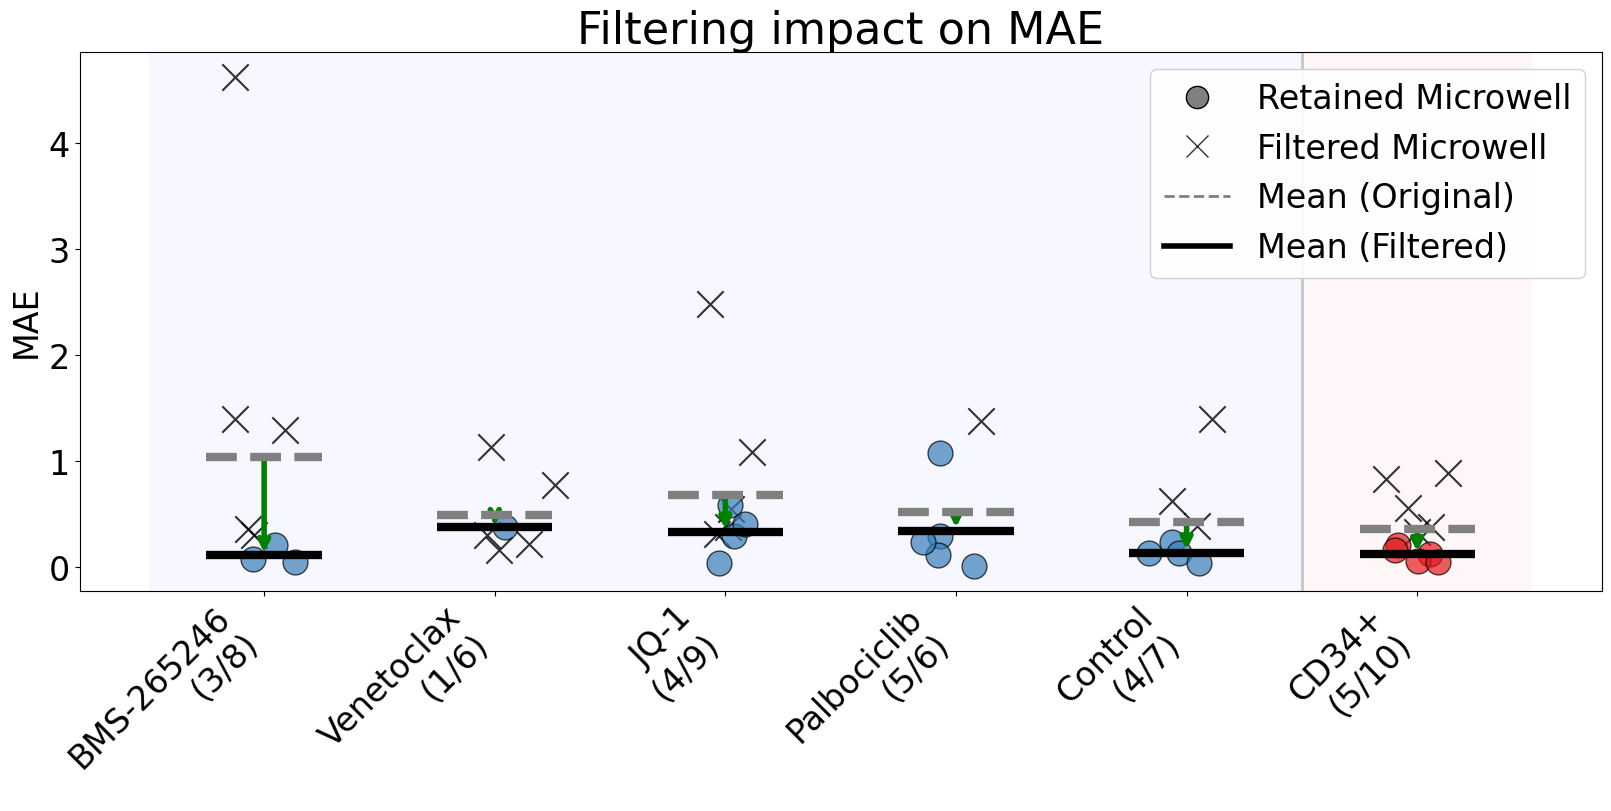

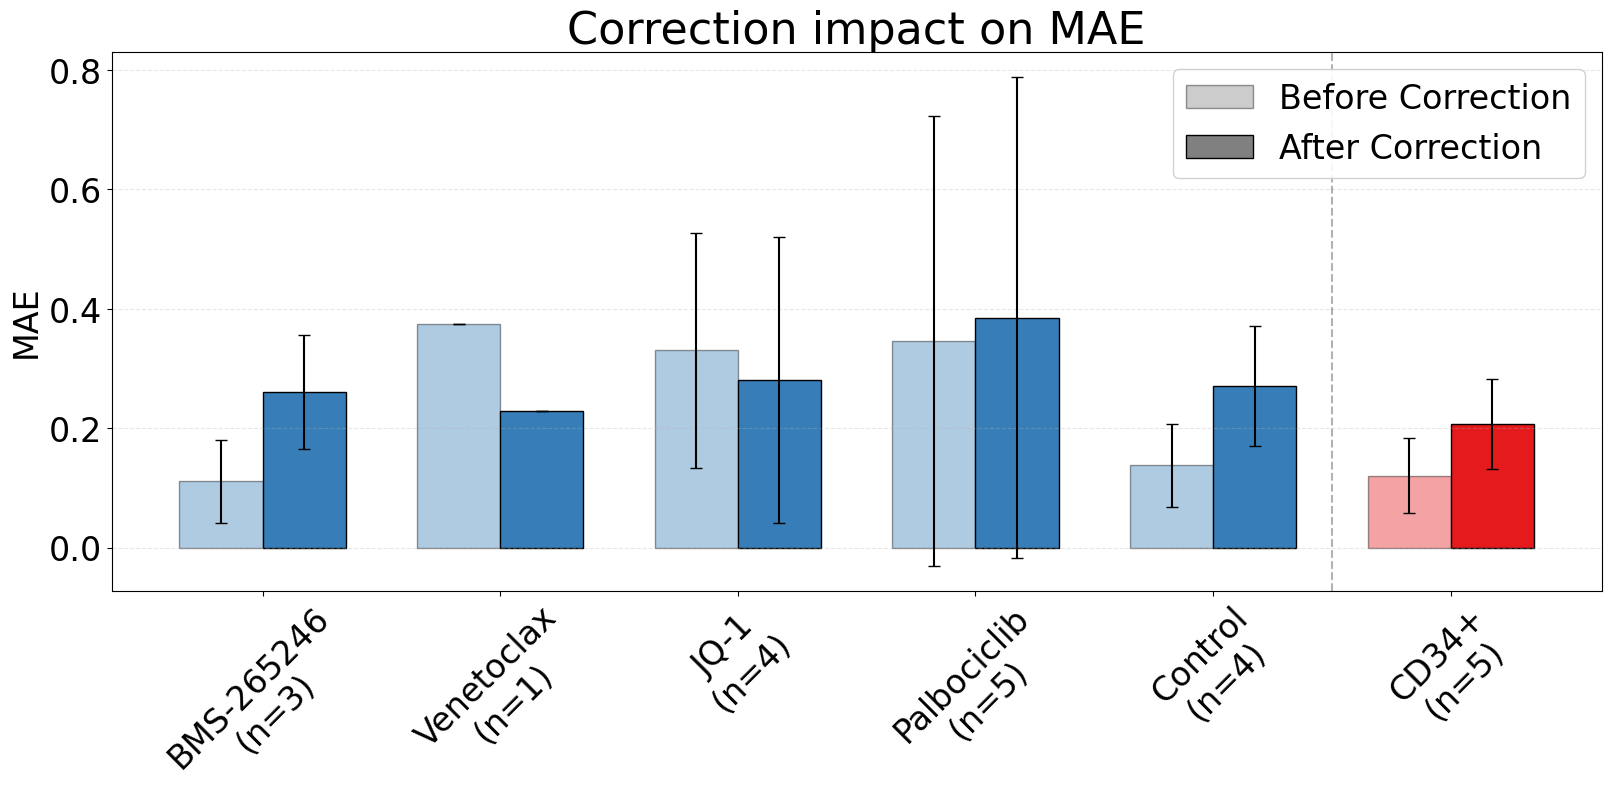

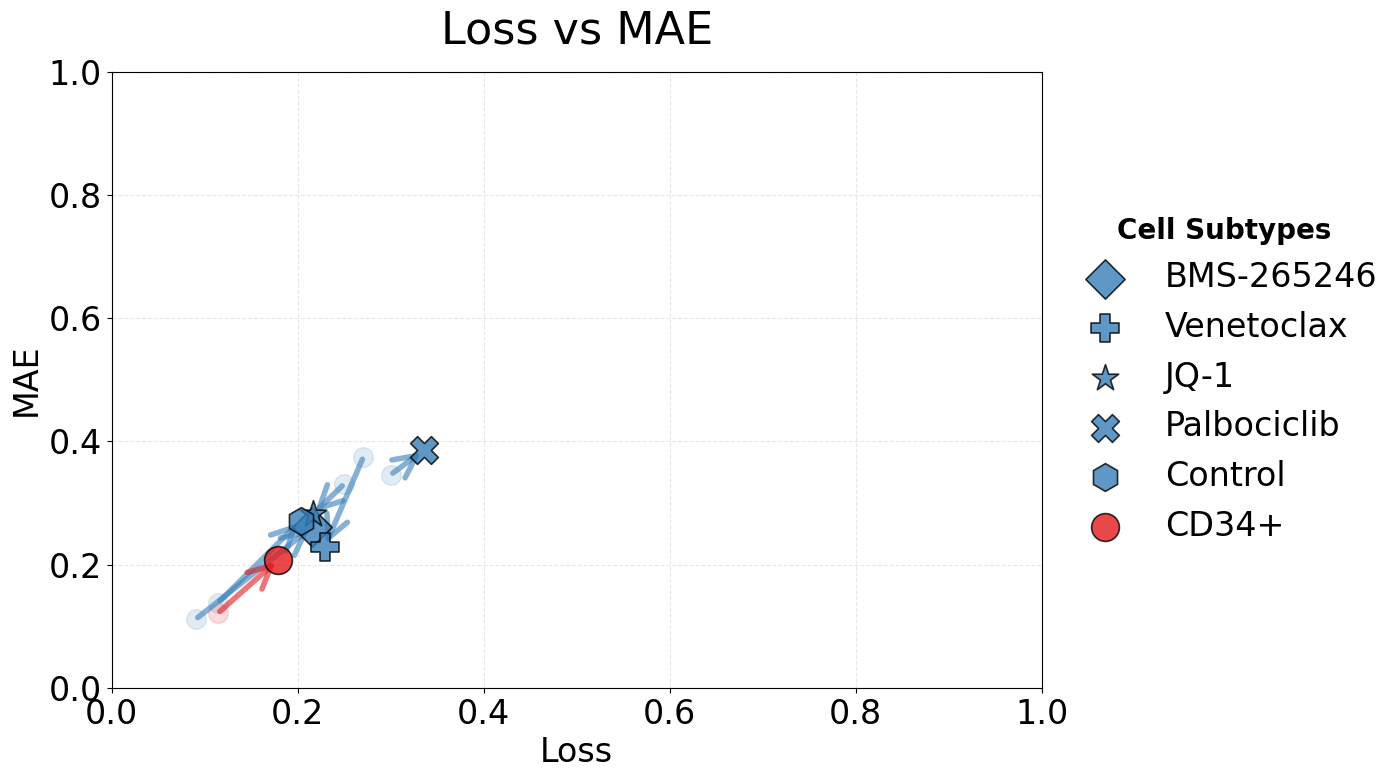

In [18]:
_ = plot_filtering_impact(grouped_all_results_wof_bc, grouped_all_results_wtf_bc,\
                             y_var = "mean_error", y_label = "MAE",\
                            datatype_groups=datatype_groups, label_map=label_map,\
                            title="Filtering impact on MAE",\
                            name_fig = "fig_cellpose_wof_vs_wfc_thresh02_all_mea")

_ = plot_grouped_performance(grouped_all_results_wtf_bc, grouped_all_results_wtf_ac,\
                             y_var = "mean_error", y_label = "MAE",\
                            datatype_groups=datatype_groups, label_map=label_map,\
                            title="Correction impact on MAE",
                            name_fig="fig_cellpose_bc_vs_ac_thresh02_all_mea")


_ = plot_vector_shift_performance(
    grouped_filter = grouped_all_results_wtf_bc, # After Filtering, Before Correction
    grouped_corr   = grouped_all_results_wtf_ac, # After Filtering, After Correction
    datatype_groups = datatype_groups,
    marker_map = marker_map,
    label_map = label_map,
    title = "Loss vs MAE",
    name_fig = "fig_cellpose_bc_vs_ac_thresh02_all_mea_sp"
)





# YOLO

## Yolo results

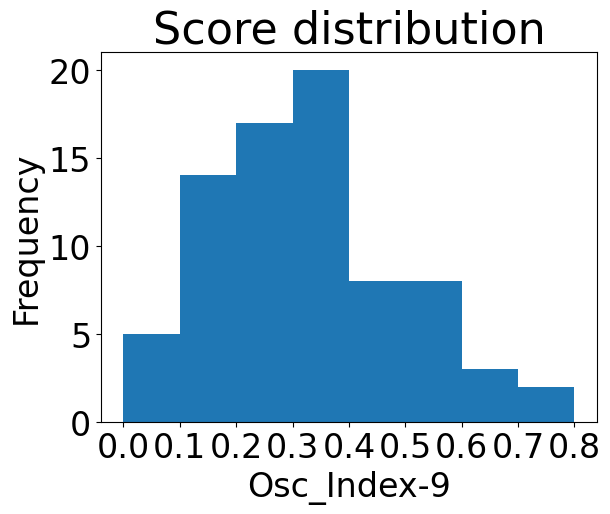

No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blo

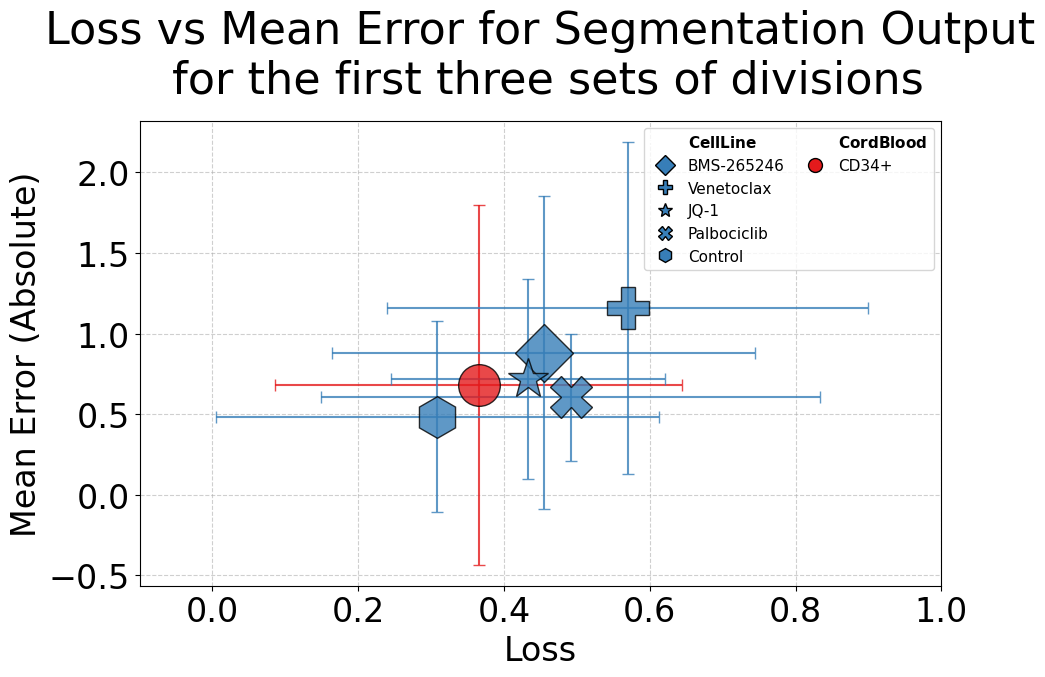

In [19]:

### Ultralytics V11
from functions.functions_segmentation_benchmark import obtain_output_inference, compute_score_column, apply_correction, extract_key

ultralytics_results = r"..\groundtruth\YOLO\yolov11" #"/Users/tizia/Documents/Curie/StemCells/Python/Results python" # to obtain
df_ultra_bc =obtain_output_inference(ultralytics_results, col_name="Output YOLO")
# curve correction
df_corrected = df_ultra_bc.apply(apply_correction, axis=0)
# create new df with df_score: I need corrected counts for this
df_score = pd.DataFrame(
    {col: [compute_score_column(col, df_ultra_bc, df_corrected)] for col in df_ultra_bc.columns}
)

# plot the distribution of the score
scores_series = df_score.iloc[0]  # I take the first column as series
xmin = math.floor(scores_series.min() * 10) / 10
xmax = math.ceil(scores_series.max() * 10) / 10
bin_edges = np.arange(xmin, xmax + 0.1, 0.1)
plt.hist(scores_series, bins=bin_edges)
plt.xticks(bin_edges)
plt.xlabel("Osc_Index-9")   
plt.ylabel("Frequency")             
plt.title("Score distribution")
plt.show()


# Select only the columns present in the cellpose dataframe (the ones with a key that is in the cellpose dataframe)
name_columns_good = df_cellpose_wof_bc.columns # df_cellpose_wtf_bc.columns
good_keys = set(
    extract_key(c) for c in name_columns_good
    if extract_key(c) is not None
)
df_keys = {
    col: extract_key(col)
    for col in df_ultra_bc.columns
}
sorted(set(df_keys.values()) & good_keys)
cols_to_keep = [
    col for col, key in df_keys.items()
    if key in good_keys
]
df_ultra_bc = df_ultra_bc[cols_to_keep]


# filter based on score
# I keep thresh=0 because otherwise I lose 13 microwells for yolo
thresh = 0
final_columns = [
    col for col in df_ultra_bc.columns 
    if (scores_series[col] > thresh)
]
df_ultra_bc_final = df_ultra_bc[final_columns]
df_ultra_bc_final = df_ultra_bc.copy()

# obtain the results for the filtered dataframe
_, df_yolo_wof_bc, _, grouped_yolo_results_wof_bc = workflow_segmentation_error(None, df_results=df_ultra_bc_final, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="nine",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map = marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_yolo_bc_thresh02_nine_loss_mea_aggrmean")





Import new iteration

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile088_c3_HSC_2000
No GT match found f

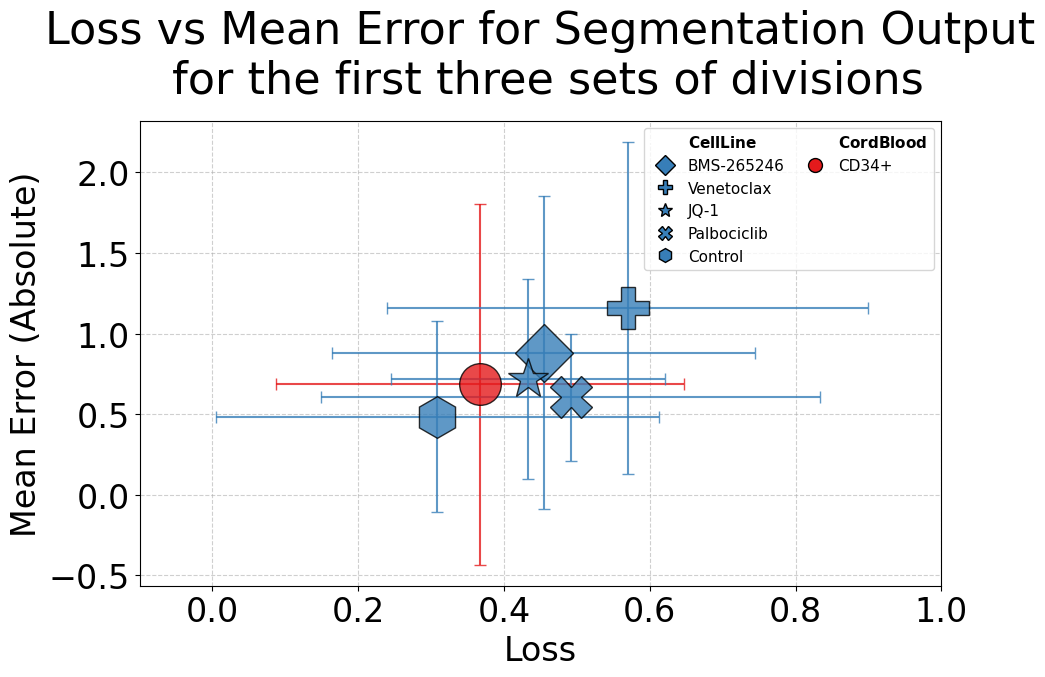

In [20]:
yolo_results = r"..\groundtruth\comparison_models\output\yolov11"
_, df_yolo_wof_bc_repl, _, grouped_yolo_results_wof_bc_repl = workflow_segmentation_error(yolo_results, df_results=None, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="nine",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_yolo_bc_thresh02_nine_loss_mea_aggrmean_post")

In [21]:
name_columns_good = [c.removesuffix("_GT") for c in df_cellpose_wof_bc.columns]

common = [c for c in name_columns_good if c in df_yolo_wof_bc_repl.columns]
df_yolo_wof_bc_matched = df_yolo_wof_bc_repl[common]

In [22]:
import pandas as pd

a = df_yolo_wof_bc_matched
b = df_yolo_wof_bc        

# 1. Quick check: same shape, same columns, same values (NaN == NaN counts as equal)
print(a.shape, b.shape)
print(a.equals(b))

(122, 77) (122, 77)
False


In [23]:
import numpy as np

A = a.to_numpy(dtype=float)
B = b.to_numpy(dtype=float)

print(A.shape, B.shape)
#diff = ~((A == B) | (np.isnan(A) & np.isnan(B)))
#print("Cells that differ:", int(diff.sum()))

#for r, c in zip(*diff.nonzero()):
#    print("col", c, "| row", r, "|", A[r, c], "vs", B[r, c])
#    print("   a:", a.columns[c])
#    print("   b:", b.columns[c])

(122, 77) (122, 77)


For corrected counts

No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000_YV11
No GT match found for Pos_yolov11best_output_sherlock_MB_251003_cord_blo

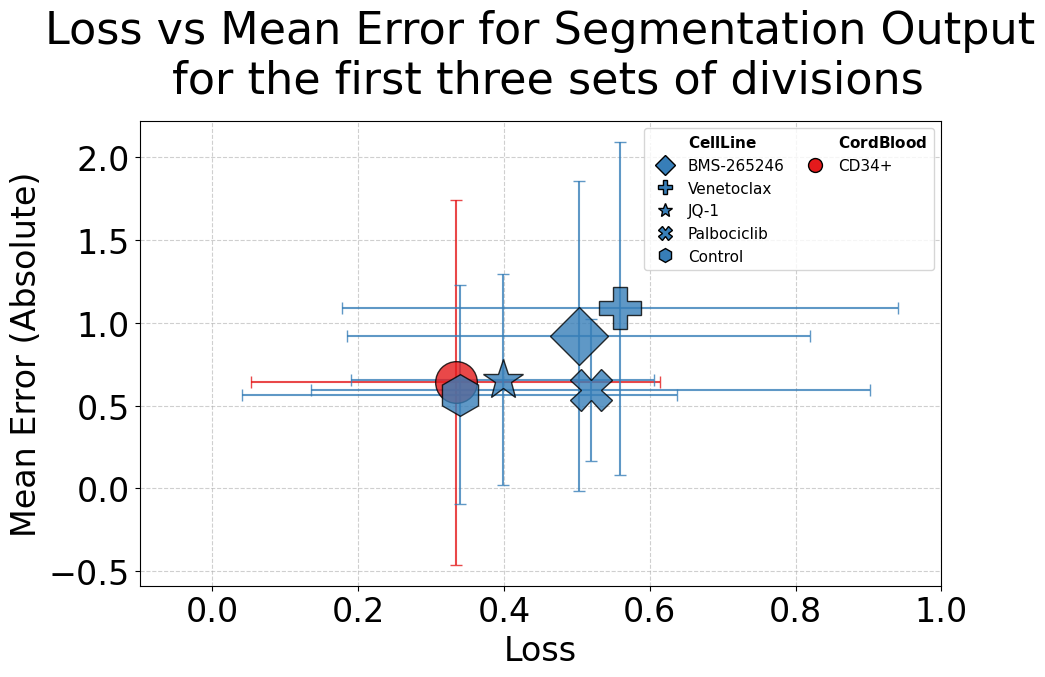

In [24]:
df_ultra_ac = df_corrected[cols_to_keep]
# obtain the results for the corrected dataframe
_, df_yolo_wof_ac, _, grouped_yolo_results_wof_ac = workflow_segmentation_error(None, df_results=df_ultra_ac, df_gt=df_gt, col_name="Output YOLO",\
                            flag_filter=False, thresh_score=None, name_index = None, comp_type="nine",\
                            x_var_name="Loss", y_var_name="mean_error",\
                            title_plot="Loss vs Mean Error for Segmentation Output\n for the first three sets of divisions",\
                            x_label="Loss", y_label="Mean Error (Absolute)",\
                            datatype_groups=datatype_groups, label_map=label_map, marker_map = marker_map,\
                            mode_aggregation="aggr_mean",\
                            flag_save=True, path_save = path_save, name_fig = "fig_yolo_ac_thresh02_nine_loss_mea_aggrmean")


Verify same numbers of microwells across architectures

In [25]:
sz_df_cellpose = df_cellpose_wof_bc.shape
sz_df_yolo = df_yolo_wof_bc.shape
print(sz_df_cellpose)
print(sz_df_yolo)
assert sz_df_cellpose == sz_df_yolo, "The two dataframes have different shapes. Check the filtering step."

sz_df_cellpose_ac = df_cellpose_wof_ac.shape
sz_df_yolo_ac = df_yolo_wof_ac.shape
print(sz_df_cellpose_ac)
print(sz_df_yolo_ac)
assert sz_df_cellpose_ac == sz_df_yolo_ac, "The two dataframes have different shapes. Check the filtering step."



(122, 77)
(122, 77)
(122, 77)
(122, 77)


## Comparison best yolo vs best cellpose

Before correction

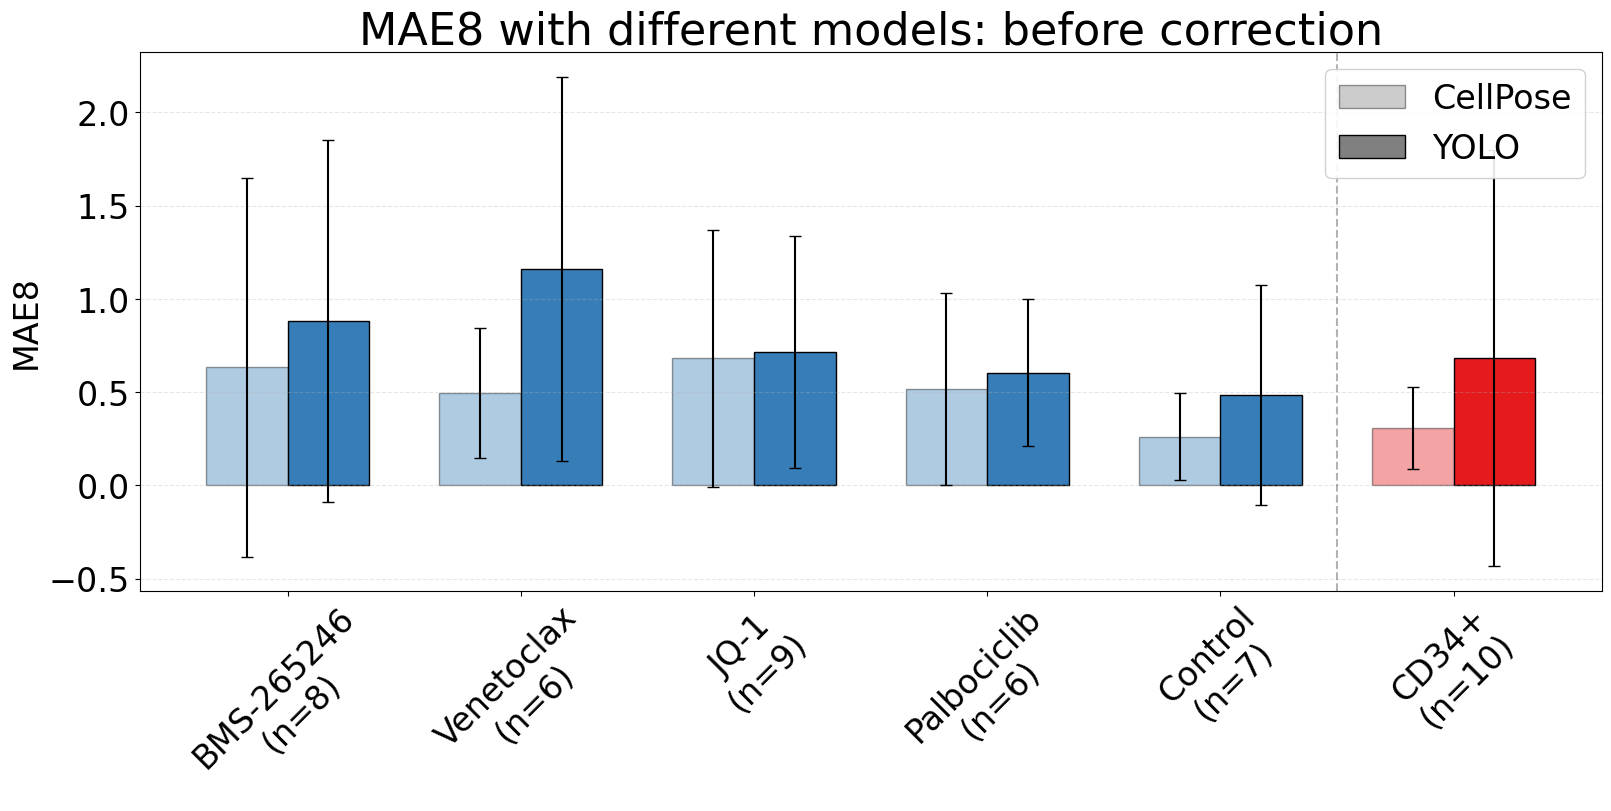

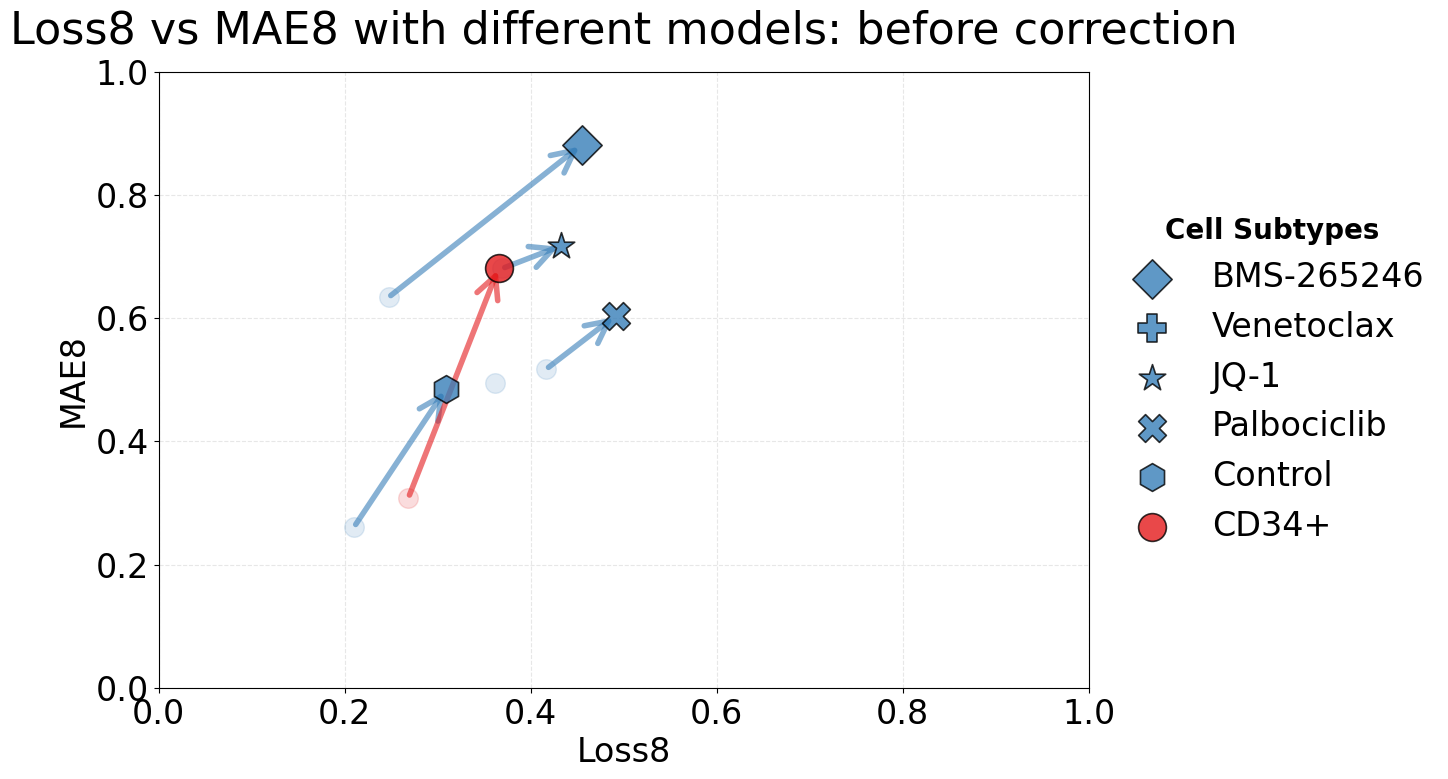

In [26]:
# before : grouped_results_wtf_bc instead of grouped_results_wof_bc
_ = plot_grouped_performance(grouped_results_wof_bc, grouped_yolo_results_wof_bc,\
                             y_var = "mean_error", y_label = "MAE8",\
                            datatype_groups=datatype_groups, label_map=label_map,\
                            title="MAE8 with different models: before correction",
                            name_fig="fig_bestcellpose_vs_bestyolo_thresh02_nine_mea",
                            custom_label1="CellPose", custom_label2="YOLO")
_ = plot_vector_shift_performance(
    grouped_filter = grouped_results_wof_bc, # cellpose model without filtering, before correction
    grouped_corr   = grouped_yolo_results_wof_bc, # yolo model, before correction
    datatype_groups = datatype_groups,
    marker_map = marker_map,
    label_map = label_map,
    x_title = "Loss8",
    y_title = "MAE8",
    title = "Loss8 vs MAE8 with different models: before correction",
    name_fig = "fig_bestcellpose_vs_bestyolo_thresh02_nine_mea_sp"
)


After correction

In [27]:
grouped_results_wof_ac

{'HPC_3000': [{'gt': '(HPC_3000)_tile008_e2',
   'index_exact': 0.6721,
   'std': np.float64(0.5002),
   'mean_error': np.float64(0.32786885245901637),
   'mean_error_norm': np.float64(0.27595628415300544)},
  {'gt': '(HPC_3000)_tile019_c2',
   'index_exact': 0.7951,
   'std': np.float64(0.4608),
   'mean_error': np.float64(0.21311475409836064),
   'mean_error_norm': np.float64(0.05006830601092895)},
  {'gt': '(HPC_3000)_tile021_d3',
   'index_exact': 0.7951,
   'std': np.float64(0.5492),
   'mean_error': np.float64(0.23770491803278687),
   'mean_error_norm': np.float64(0.07775175644028103)},
  {'gt': '(HPC_3000)_tile033_d1',
   'index_exact': 0.7951,
   'std': np.float64(0.4187),
   'mean_error': np.float64(0.20491803278688525),
   'mean_error_norm': np.float64(0.06147540983606557)},
  {'gt': '(HPC_3000)_tile053_b4',
   'index_exact': 0.9451,
   'std': np.float64(0.7466),
   'mean_error': np.float64(0.14285714285714285),
   'mean_error_norm': np.float64(0.02980115122972266)},
  {'gt':

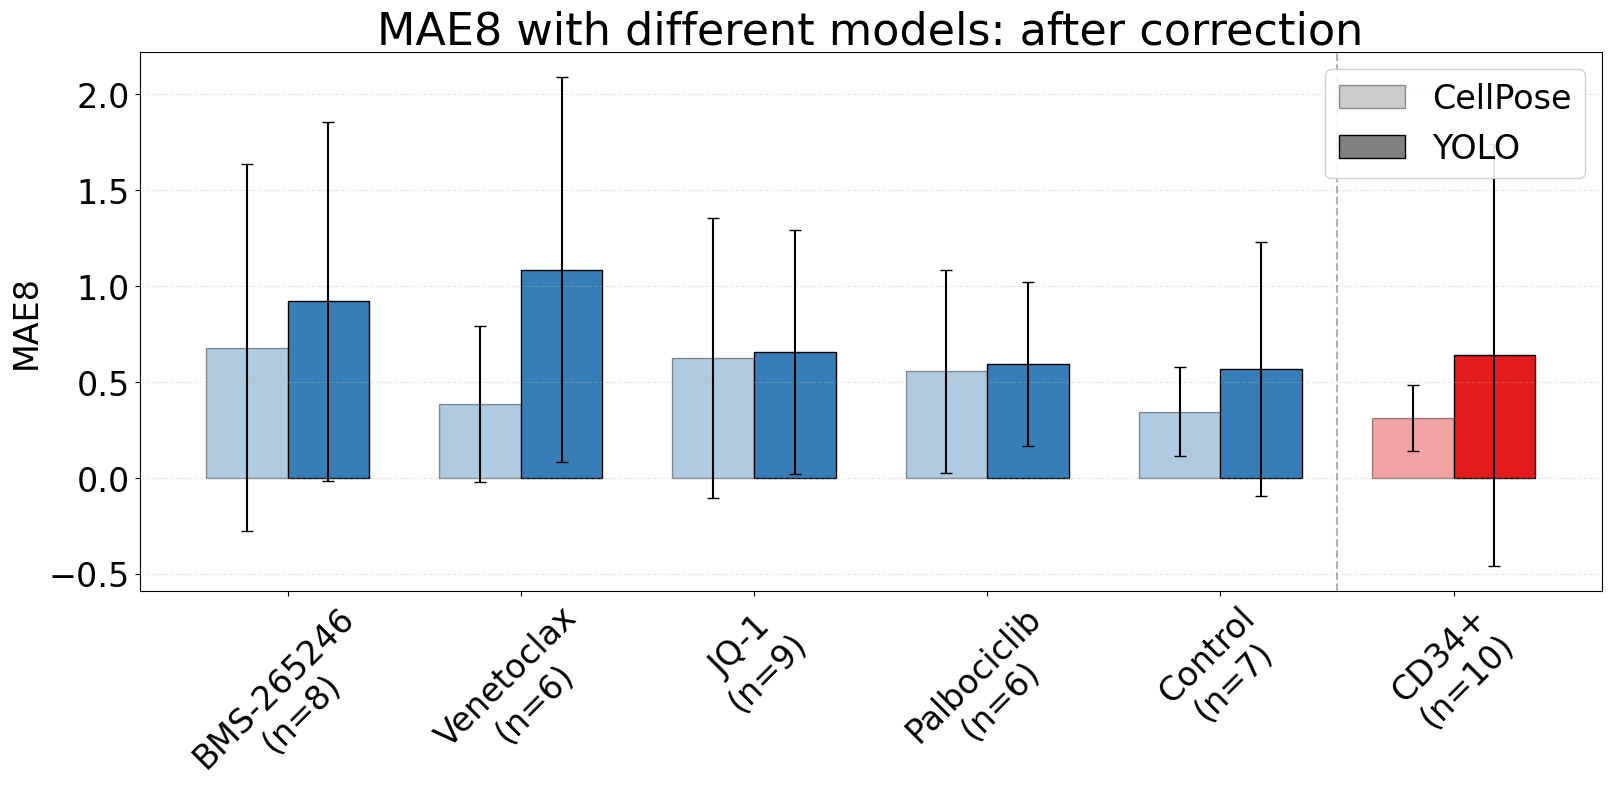

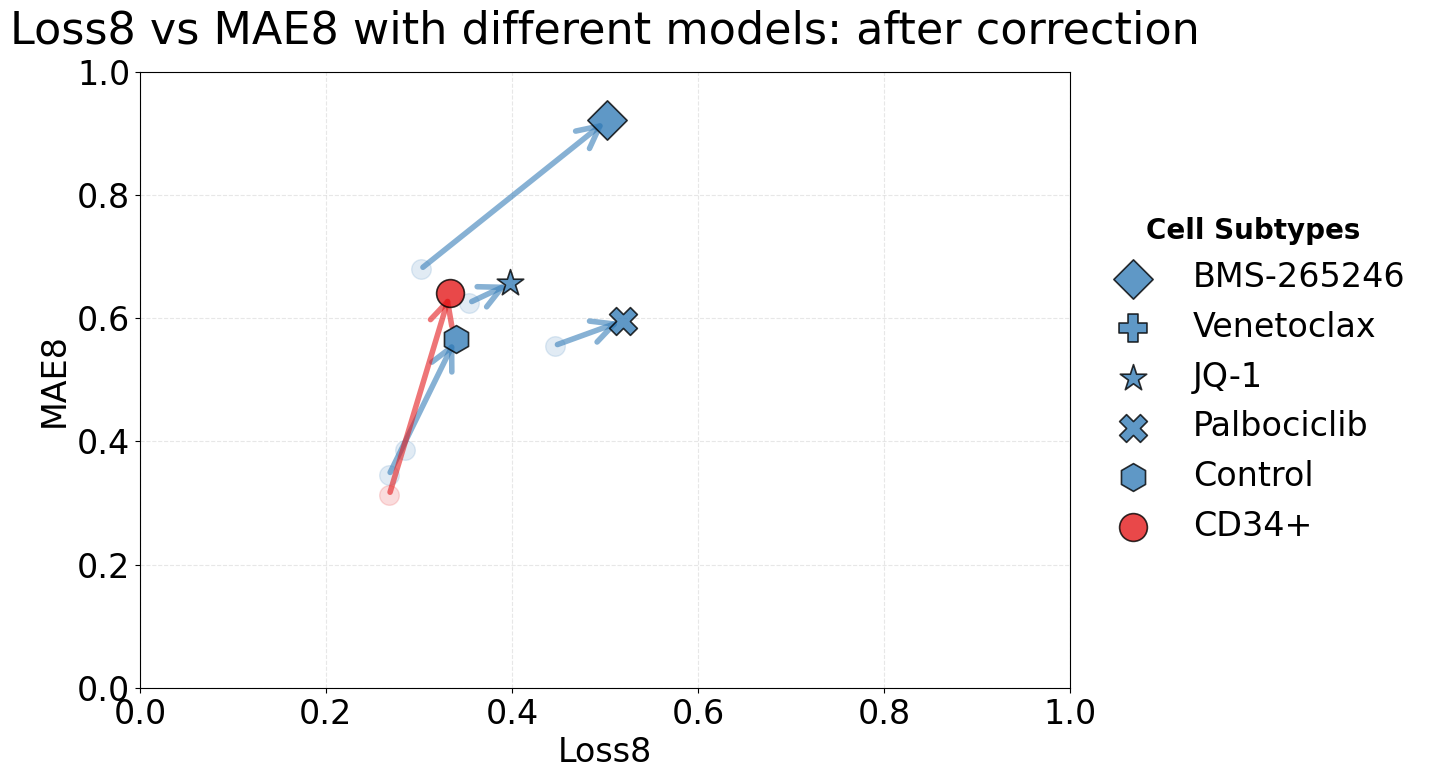

In [28]:
# before: grouped_results_wtf_ac instead of grouped_results_wof_ac
_ = plot_grouped_performance(grouped_results_wof_ac, grouped_yolo_results_wof_ac,\
                             y_var = "mean_error", y_label = "MAE8",\
                            datatype_groups=datatype_groups, label_map=label_map,\
                            title="MAE8 with different models: after correction",
                            name_fig="fig_bestcellpose_vs_bestyolo_thresh02_nine_mea_ac",
                            custom_label1="CellPose", custom_label2="YOLO")
_ = plot_vector_shift_performance(
    grouped_filter = grouped_results_wof_ac, # cellpose model with filtering, before correction
    grouped_corr   = grouped_yolo_results_wof_ac, # yolo model, before correction
    datatype_groups = datatype_groups,
    marker_map = marker_map,
    label_map = label_map,
    x_title = "Loss8",
    y_title = "MAE8",
    title = "Loss8 vs MAE8 with different models: after correction",
    name_fig = "fig_bestcellpose_vs_bestyolo_thresh02_nine_mea_sp_ac"
)


## Comparison with other models

['cellposesam', 'microsam', 'yolov11']
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


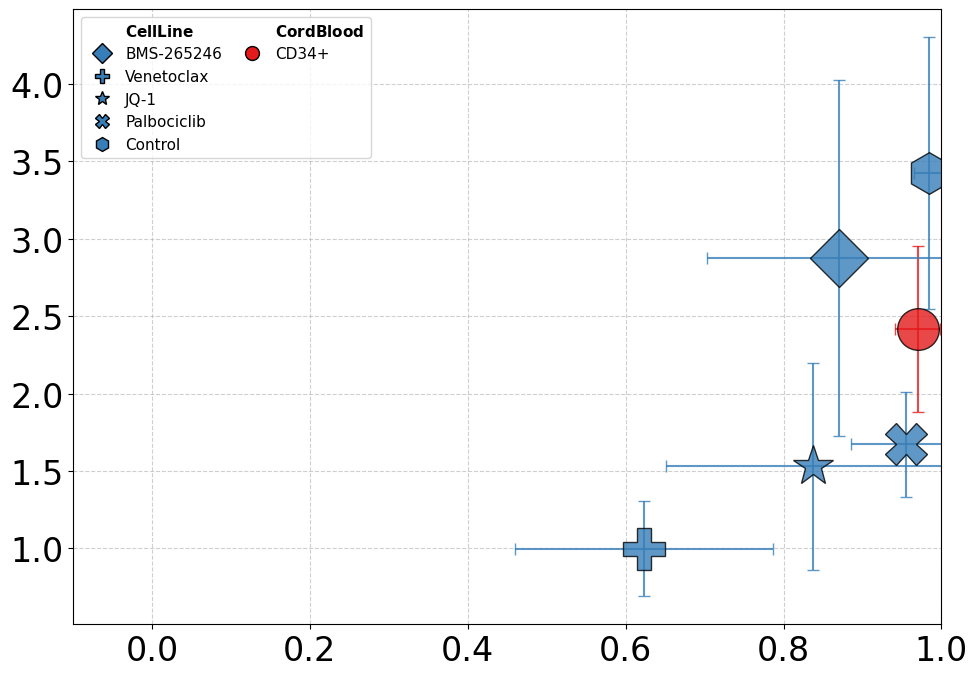

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009
Conditions found: ['HPC_3000', 'TR1-A01', 'TR3-A03', 'TR5-B04', 'TR7-B02', 'TR9-C01']


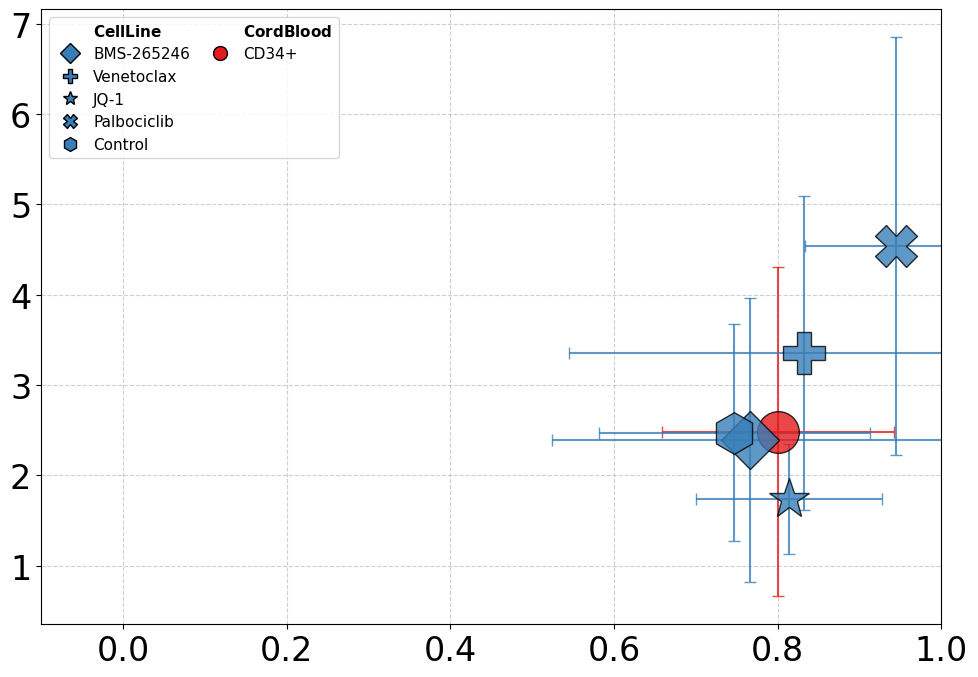

No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile044_a2_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile055_d3_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile059_b2_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile072_b3_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile074_c2_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile078_e3_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile084_c4_HSC_2000
No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HSC_2000)_tile088_c3_HSC_2000
No GT match found f

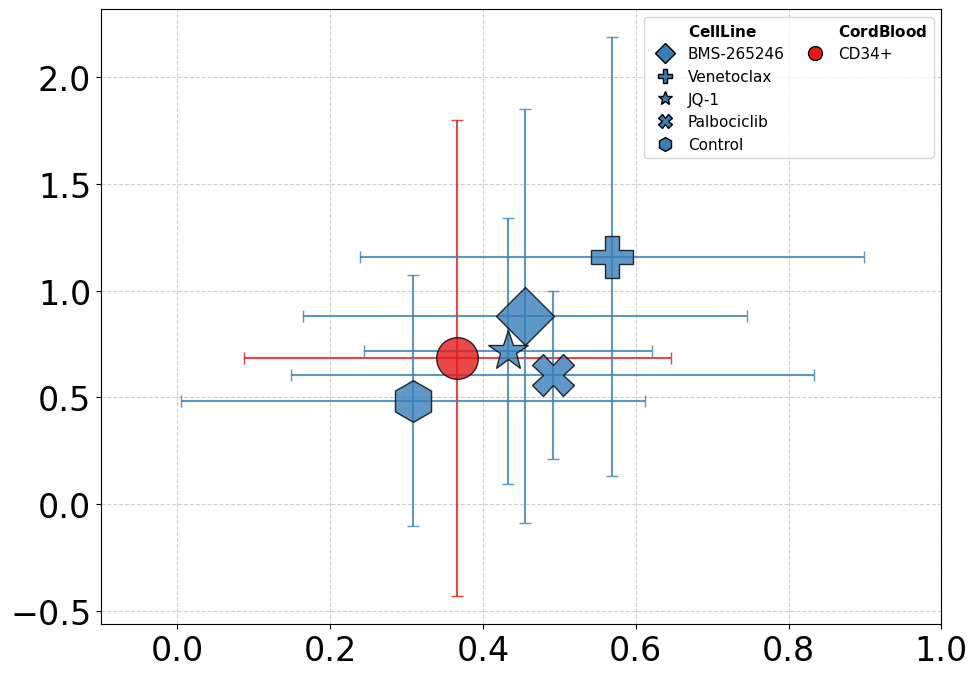

In [29]:
import os

root = r"..\groundtruth\comparison_models\output"
models = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
print(models)   # check these are the 3 model folders

grouped_all = {}
for m in models:
    _, _, _, grouped = workflow_segmentation_error(
        os.path.join(root, m), df_results=None, df_gt=df_gt, col_name="Output YOLO",
        flag_filter=False, thresh_score=None, name_index=None, comp_type="nine",
        x_var_name="Loss", y_var_name="mean_error", title_plot="", x_label="", y_label="",
        datatype_groups=datatype_groups, label_map=label_map, marker_map=marker_map,
        mode_aggregation="aggr_mean", flag_save=False, path_save=path_save,
        name_fig="tmp")
    grouped_all[m] = grouped
grouped_all["cellposesam_trained"] = grouped_results_wof_bc   # name is the legend label
# modify keys
grouped_all["cellposesam_zeroshot"] = grouped_all.pop("cellposesam")
grouped_all["microsam_zeroshot"] = grouped_all.pop("microsam")
grouped_all["yolov11_trained"] = grouped_all.pop("yolov11")

In [30]:
def restrict_to_common(grouped_all):
    common = None
    for g in grouped_all.values():
        keys = {(grp, d["gt"]) for grp, lst in g.items() for d in lst}
        common = keys if common is None else common & keys
    return {
        m: {grp: [d for d in lst if (grp, d["gt"]) in common] for grp, lst in g.items()}
        for m, g in grouped_all.items()
    }, common

grouped_common, common = restrict_to_common(grouped_all)
print(len(common), "tiles shared by all models")
for m, g in grouped_all.items():
    print(m, sum(len(v) for v in g.values()), "tiles before restriction")

46 tiles shared by all models
cellposesam_trained 46 tiles before restriction
cellposesam_zeroshot 46 tiles before restriction
microsam_zeroshot 46 tiles before restriction
yolov11_trained 46 tiles before restriction


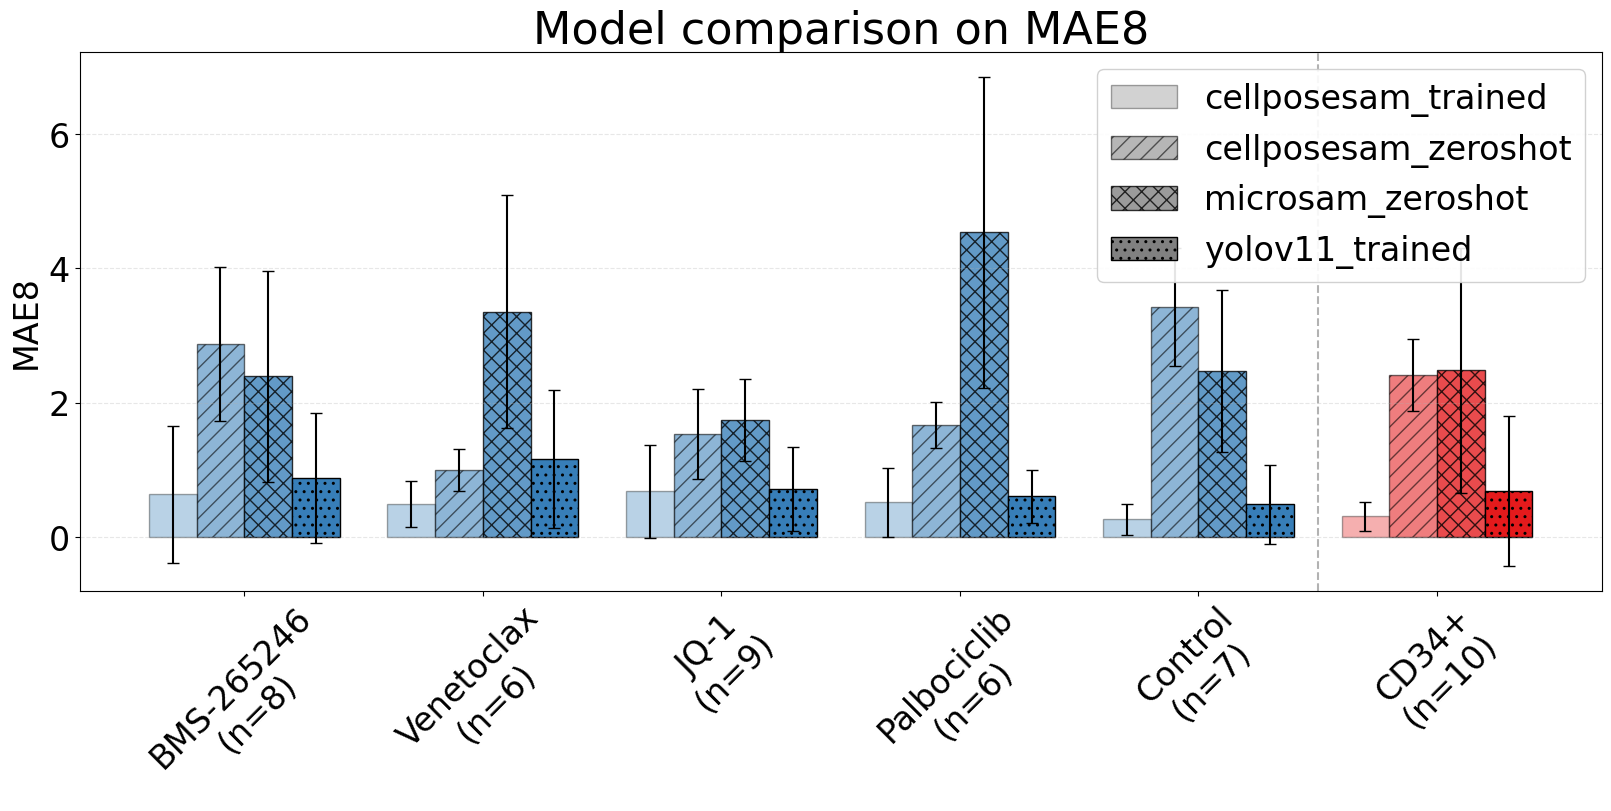

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_models_comparison(grouped_dict, datatype_groups, label_map=None,
                           y_var="mean_error", y_label="Mean Error", title=None,
                           model_labels=None, path_save=None, name_fig=None):
    scale = 4
    plt.rcParams.update({
        'font.family': 'sans-serif', 'font.size': 5*scale, 'axes.labelsize': 6*scale,
        'axes.titlesize': 8*scale, 'xtick.labelsize': 6*scale,
        'ytick.labelsize': 6*scale, 'legend.fontsize': 6*scale,
    })

    names = list(grouped_dict.keys())
    first = grouped_dict[names[0]]

    conditions, group_of = [], {}
    for gname, subtypes in datatype_groups.items():
        for st in subtypes:
            if st in first and len(first[st]) > 0:
                conditions.append(st)
                group_of[st] = gname

    n = len(names)
    x = np.arange(len(conditions))
    width = 0.8 / n
    alphas = np.linspace(0.35, 1.0, n)
    hatches = ['', '//', 'xx', '..', '\\\\', '++'][:n]
    base_colors = {'Cell Line': '#377eb8', 'Cord Blood': '#e41a1c'}
    colors = [base_colors[group_of[c]] for c in conditions]

    fig, ax = plt.subplots(figsize=(4*scale, 2*scale), layout='constrained')
    for i, m in enumerate(names):
        g = grouped_dict[m]
        means = [np.mean([s[y_var] for s in g[c]]) for c in conditions]
        stds = [np.std([s[y_var] for s in g[c]]) for c in conditions]
        offset = (i - (n - 1) / 2) * width
        ax.bar(x + offset, means, width, yerr=stds, color=colors, alpha=alphas[i],
               hatch=hatches[i], edgecolor='black', capsize=1*scale)

    labels = [f"{label_map.get(c, c) if label_map else c}\n(n={len(first[c])})"
              for c in conditions]
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

    legend = [Patch(facecolor='gray', alpha=alphas[i], hatch=hatches[i], edgecolor='black',
                    label=(model_labels or {}).get(m, m)) for i, m in enumerate(names)]
    ax.legend(handles=legend, loc='upper right', frameon=True, framealpha=0.9)

    n_first = len([c for c in conditions if group_of[c] == list(datatype_groups)[0]])
    ax.axvline(x=n_first - 0.5, color='black', linestyle='--', alpha=0.3)

    if path_save and name_fig:
        fig.savefig(os.path.join(path_save, f"{name_fig}.png"), bbox_inches='tight', dpi=300)
        fig.savefig(os.path.join(path_save, f"{name_fig}.svg"), bbox_inches='tight')
    plt.show()
    return fig

_ = plot_models_comparison(
    grouped_common, datatype_groups, label_map=label_map,
    y_var="mean_error", y_label="MAE8", title="Model comparison on MAE8",
    model_labels=None,   # e.g. {"cellposesam": "Cellpose-SAM", "yolov11": "YOLOv11"}
    path_save=path_save, name_fig="fig_models_comparison_mea")